# Data Wrangling - Préparation des données

Ce notebook contient toutes les étapes d'importation, d'exploration, de nettoyage et de préparation des données pour l'analyse de l'attrition des employés.

## 1. Importation des bibliothèques

La bibliothèque pandas est utilisée pour manipuler des DataFrames, facilitant l'analyse de données tabulaires. missingno permet de visualiser les valeurs manquantes, tandis que seaborn améliore la lisibilité des graphiques basés sur matplotlib.

Le module sklearn offre plusieurs outils de machine learning. SimpleImputer gère les valeurs manquantes, StandardScaler normalise les données, et OneHotEncoder encode les variables catégorielles. LabelEncoder transforme les étiquettes en valeurs numériques.

In [3]:
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
import numpy as np
import pickle

## 2. Importation des données

### 2.1 Données générales

Le service Ressources Humaines nous a transmis un fichier CSV contenant des données anonymisées sur les employés. Ce dataset regroupe plusieurs informations relatives aux collaborateurs de l'entreprise en 2015, ainsi que leur statut en 2016 (notamment s'ils ont quitté l'entreprise ou non).

In [4]:
# Charger le dataset
general_data = pd.read_csv('Data_origin/general_data.csv')

# Afficher les premières lignes du dataset
general_data.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,Y,11,8,0,1.0,6,1,0,0
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,0.0,Y,23,8,1,6.0,3,5,1,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,1.0,Y,15,8,3,5.0,2,5,0,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,3.0,Y,11,8,3,13.0,5,8,7,5
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,4.0,Y,12,8,2,9.0,2,6,0,4


In [5]:
# Afficher les informations du dataset
general_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

In [6]:
# Display summary statistics
general_data.describe()

,Age,DistanceFromHome,Education,EmployeeCount,EmployeeID,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
count,4410.000000,4410.000000,4410.000000,4410.0,4410.000000,4410.000000,4410.000000,4391.000000,4410.000000,4410.0,4410.000000,4401.000000,4410.000000,4410.000000,4410.000000,4410.000000
mean,36.923810,9.192517,2.912925,1.0,2205.500000,2.063946,65029.312925,2.694830,15.209524,8.0,0.793878,11.279936,2.799320,7.008163,2.187755,4.123129
std,9.133301,8.105026,1.023933,0.0,1273.201673,1.106689,47068.888559,2.498887,3.659108,0.0,0.851883,7.782222,1.288978,6.125135,3.221699,3.567327
min,18.000000,1.000000,1.000000,1.0,1.000000,1.000000,10090.000000,0.000000,11.000000,8.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,2.000000,1.0,1103.250000,1.000000,29110.000000,1.000000,12.000000,8.0,0.000000,6.000000,2.000000,3.000000,0.000000,2.000000
50%,36.000000,7.000000,3.000000,1.0,2205.500000,2.000000,49190.000000,2.000000,14.000000,8.0,1.000000,10.000000,3.000000,5.000000,1.000000,3.000000
75%,43.000000,14.000000,4.000000,1.0,3307.750000,3.000000,83800.000000,4.000000,18.000000,8.0,1.000000,15.000000,3.000000,9.000000,3.000000,7.000000
max,60.000000,29.000000,5.000000,1.0,4410.000000,5.000000,199990.000000,9.000000,25.000000,8.0,3.000000,40.000000,6.000000,40.000000,15.000000,17.000000


In [7]:
# Identifie le type des colonnes (entre numérique et catégorique)
numerical_columns = general_data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = general_data.select_dtypes(include=['object']).columns
print('numerical_columns : ', numerical_columns)
print('categorical columns : ', categorical_columns)

numerical_columns :  Index(['Age', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeID',
       'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike',
       'StandardHours', 'StockOptionLevel', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')
categorical columns :  Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18'],
      dtype='str')


C:\Users\Agordien\AppData\Local\Temp\ipykernel_25396\2780197165.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = general_data.select_dtypes(include=['object']).columns


#### Vérfication du nombre de valeur null (manquante)

In [8]:
# Afficher les valeurs manquantes
general_data.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeID                  0
Gender                      0
JobLevel                    0
JobRole                     0
MaritalStatus               0
MonthlyIncome               0
NumCompaniesWorked         19
Over18                      0
PercentSalaryHike           0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           9
TrainingTimesLastYear       0
YearsAtCompany              0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64

#### Remplissage des valeurs vide

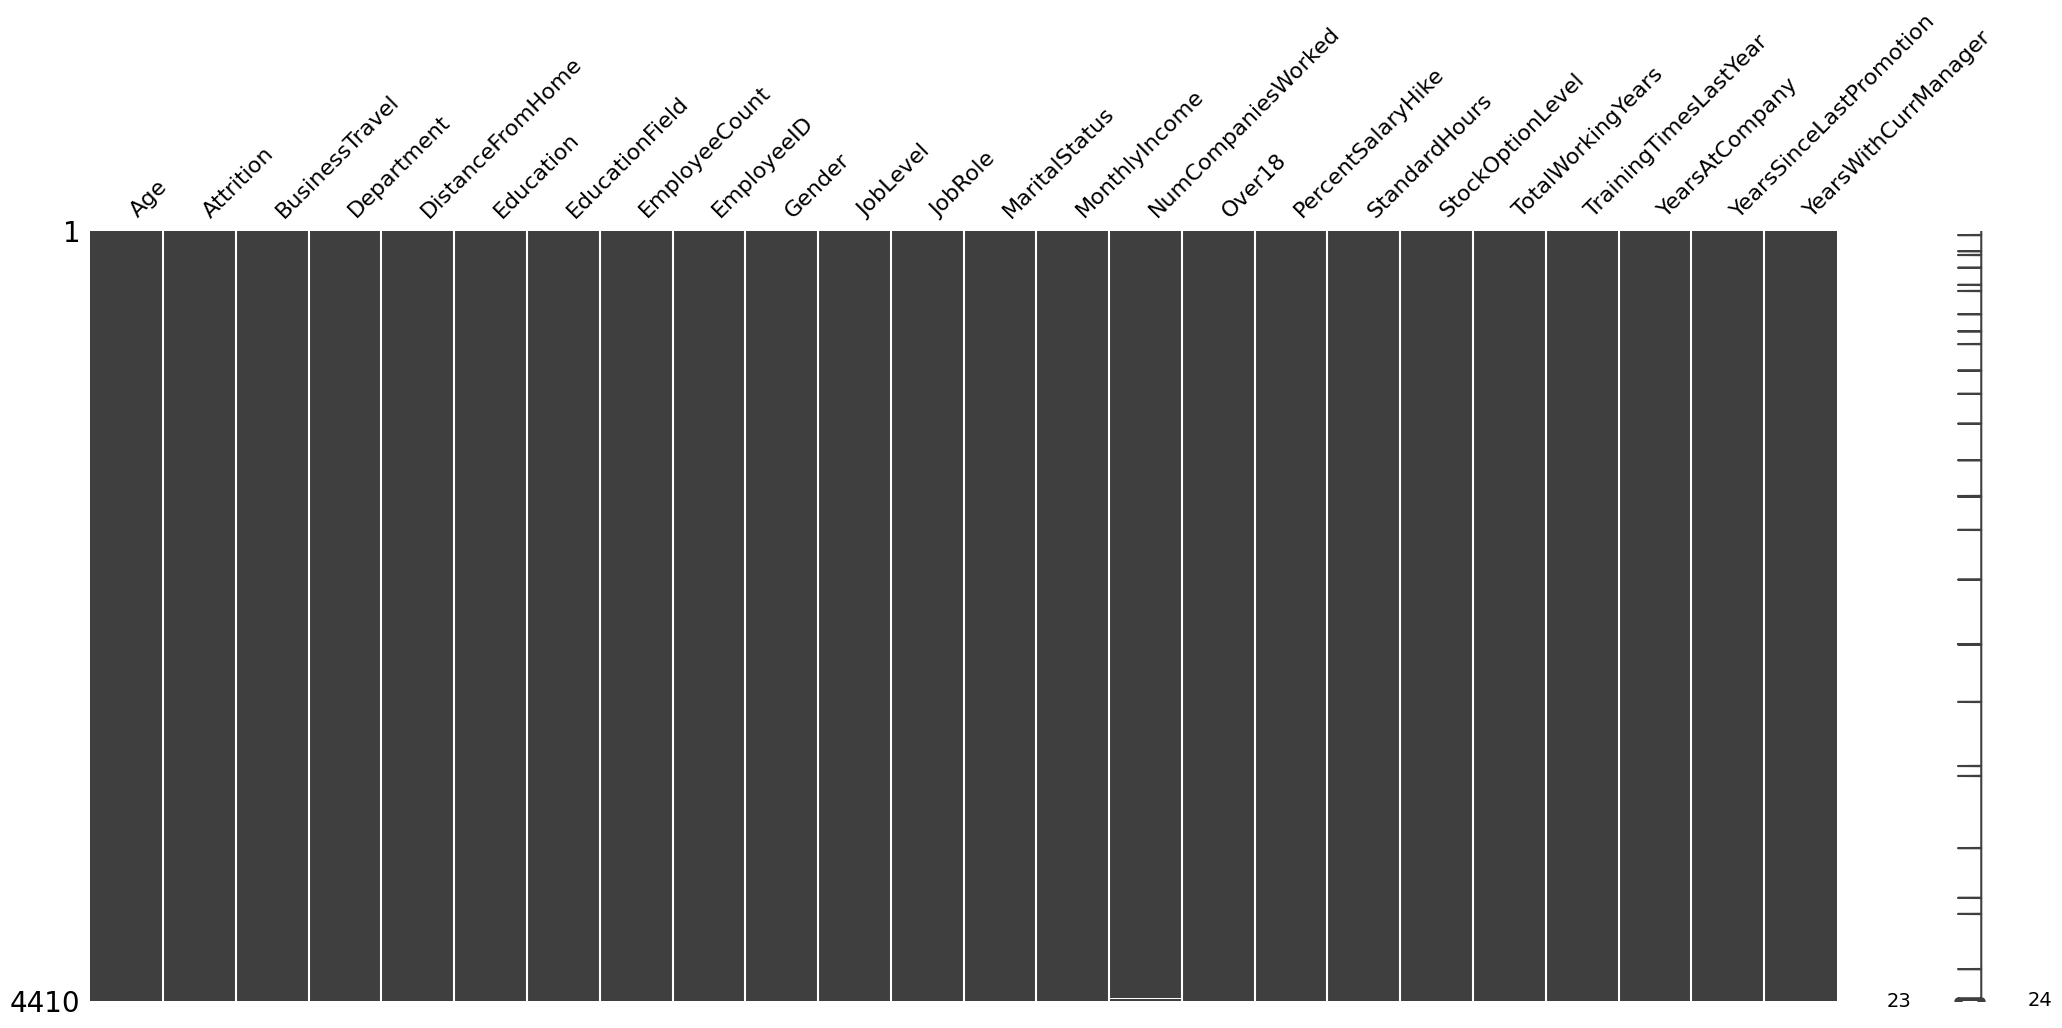

C:\Users\Agordien\AppData\Local\Temp\ipykernel_25396\515402886.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = general_data.select_dtypes(include=['object']).columns


Age                        0
DistanceFromHome           0
Education                  0
EmployeeCount              0
EmployeeID                 0
JobLevel                   0
MonthlyIncome              0
NumCompaniesWorked         0
PercentSalaryHike          0
StandardHours              0
StockOptionLevel           0
TotalWorkingYears          0
TrainingTimesLastYear      0
YearsAtCompany             0
YearsSinceLastPromotion    0
YearsWithCurrManager       0
Attrition                  0
BusinessTravel             0
Department                 0
EducationField             0
Gender                     0
JobRole                    0
MaritalStatus              0
Over18                     0
dtype: int64

In [9]:
# Visualize missing data
msno.matrix(general_data)
plt.show()
general_data_updated = general_data.copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")

general_data_num = general_data_updated.select_dtypes(include=[np.number])
imputer.fit(general_data_num)

# Remplacement des valeurs manquantes
general_data_updated = pd.DataFrame(imputer.transform(general_data_num), columns=general_data_num.columns)

# For categorical columns, use mode imputation
categorical_columns = general_data.select_dtypes(include=['object']).columns
general_data_updated[categorical_columns] = general_data[categorical_columns].fillna(general_data[categorical_columns].mode().iloc[0])

# Vérifier s'il reste des valeurs manquantes
general_data_updated.isnull().sum()

#### Analyse des données

##### Analyse univariée

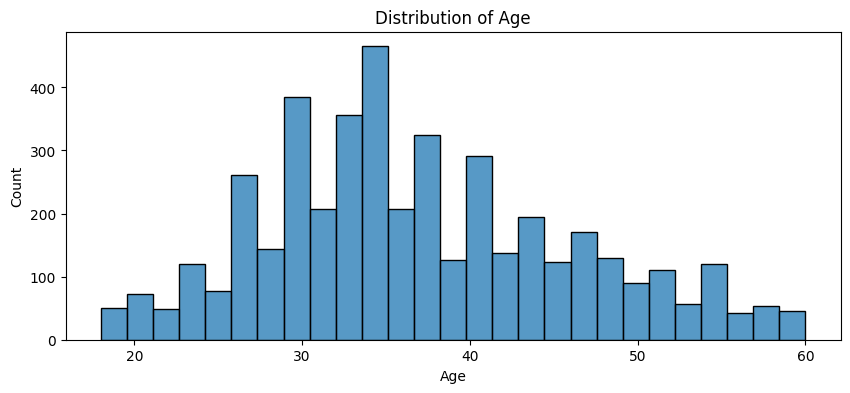

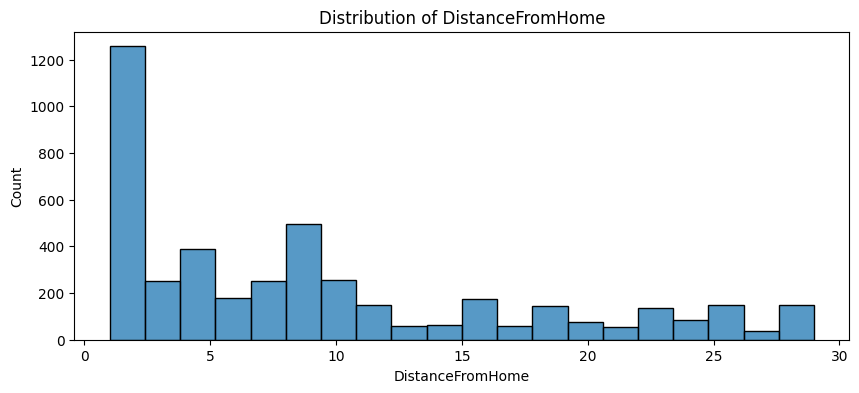

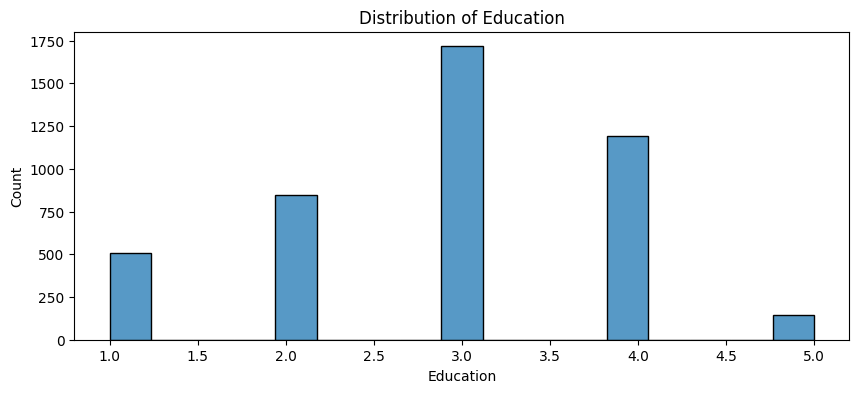

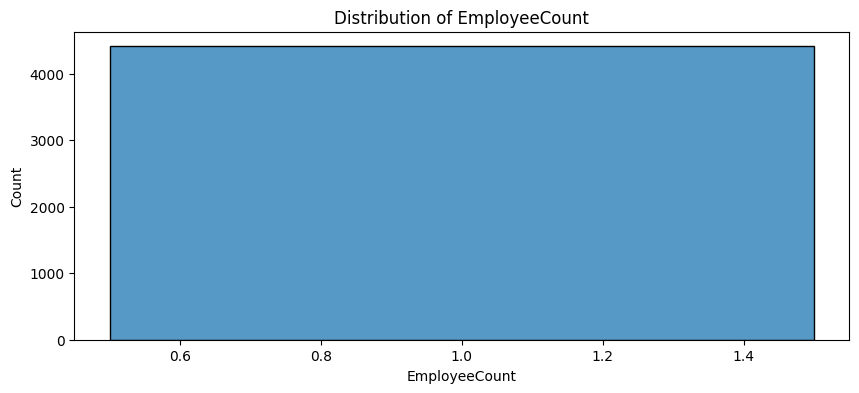

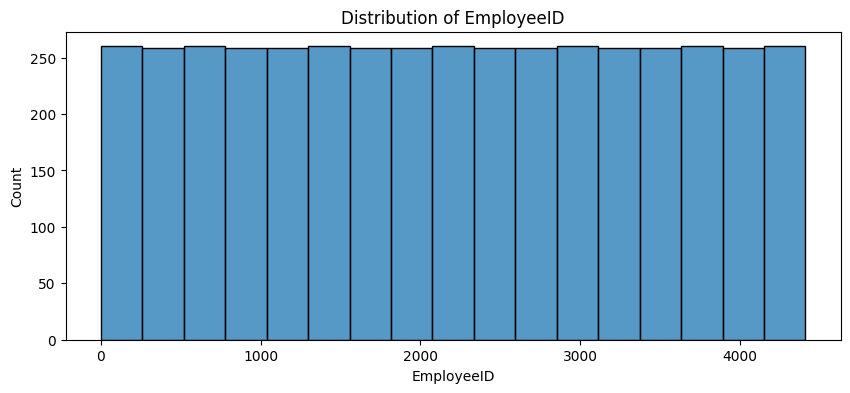

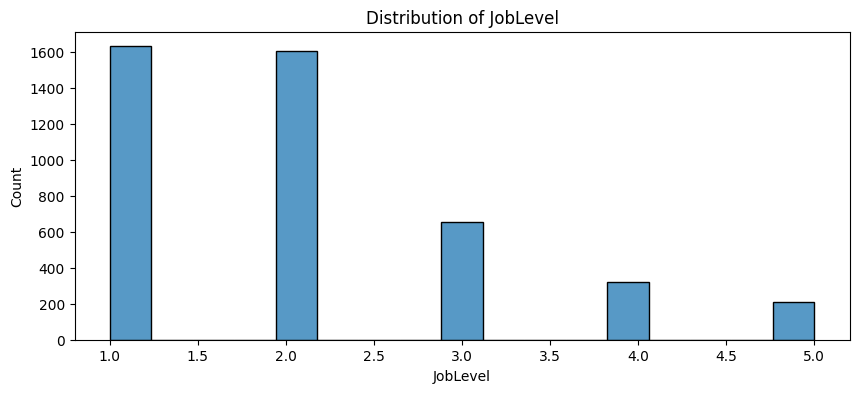

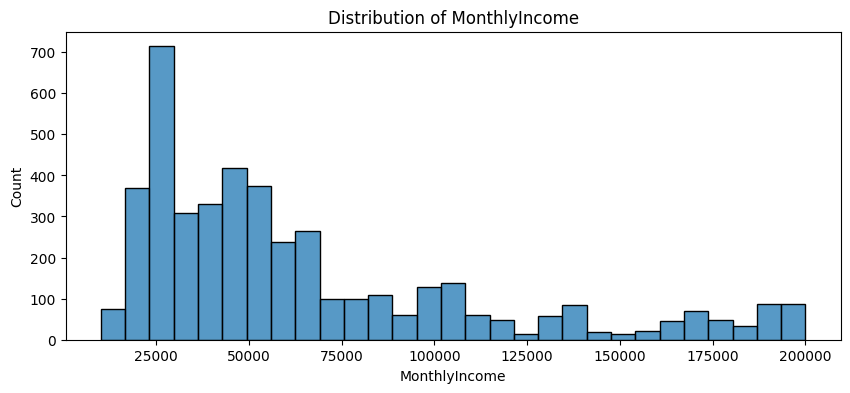

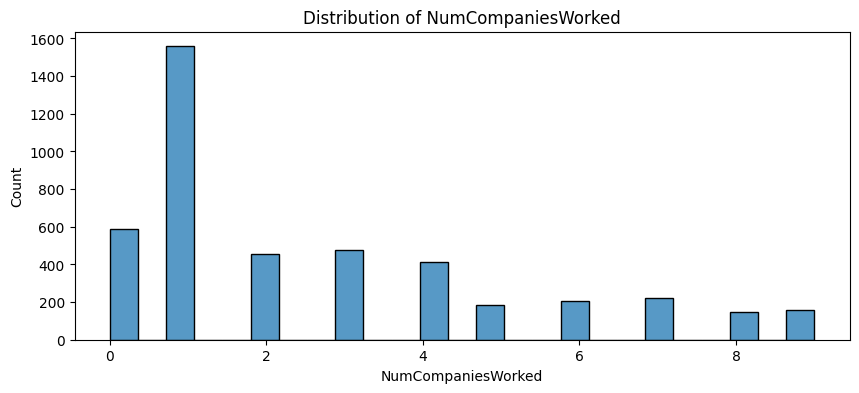

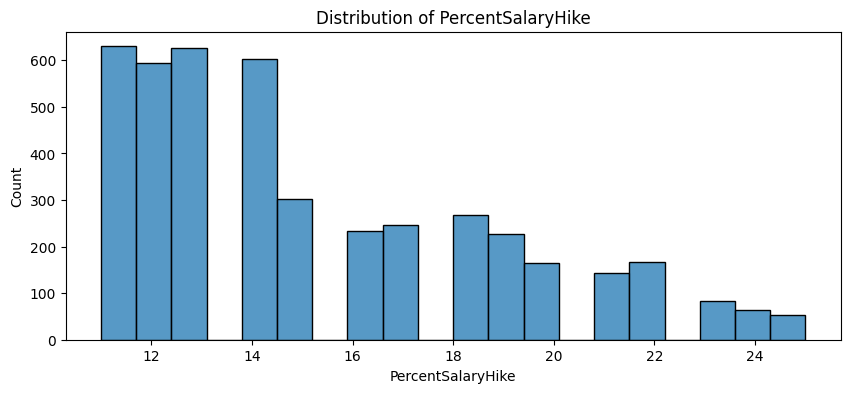

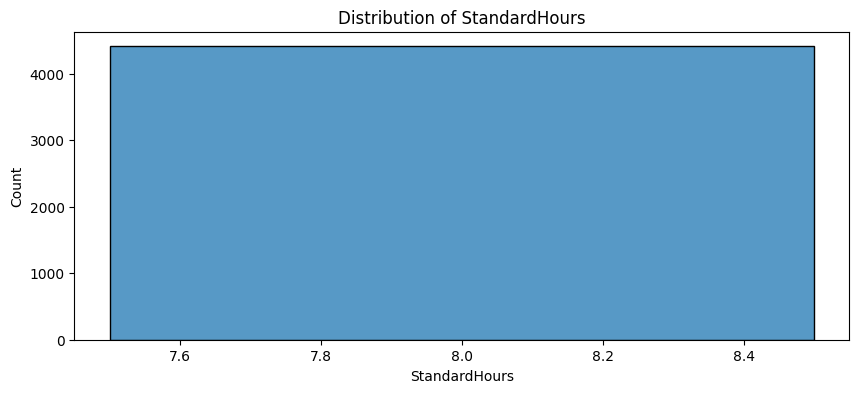

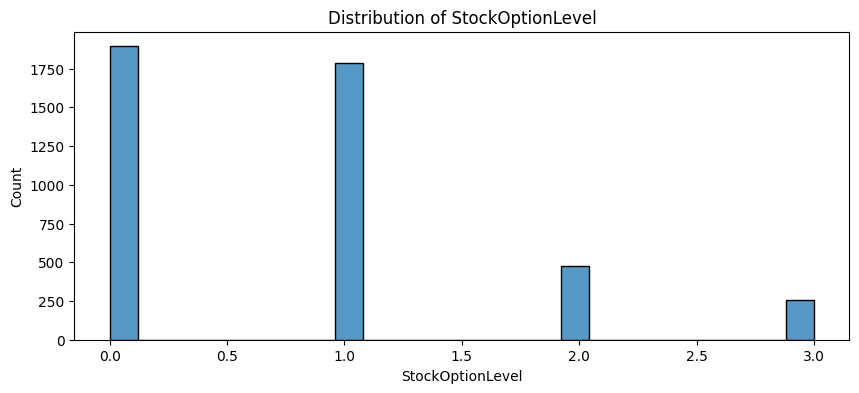

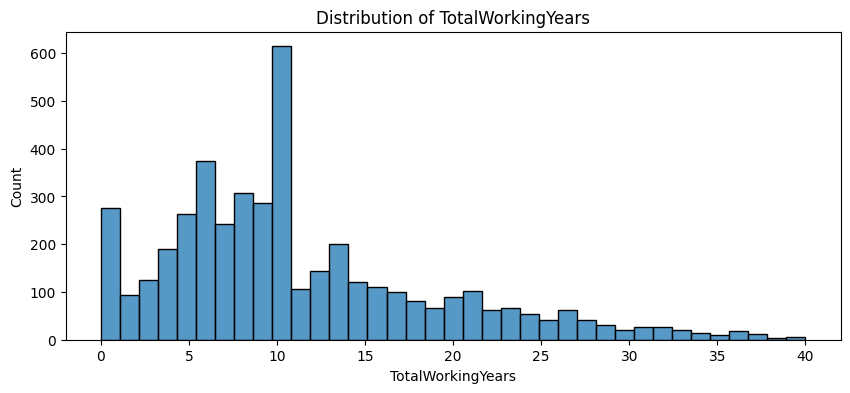

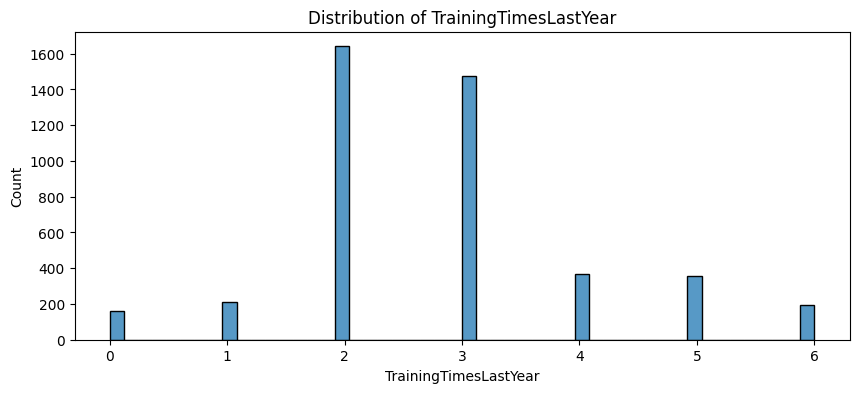

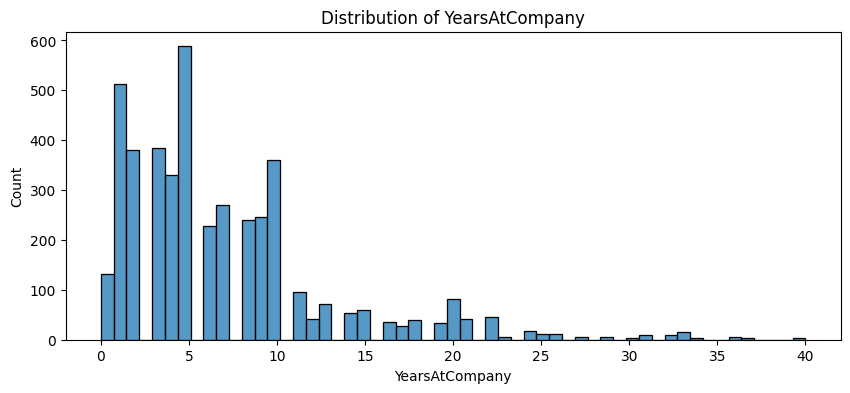

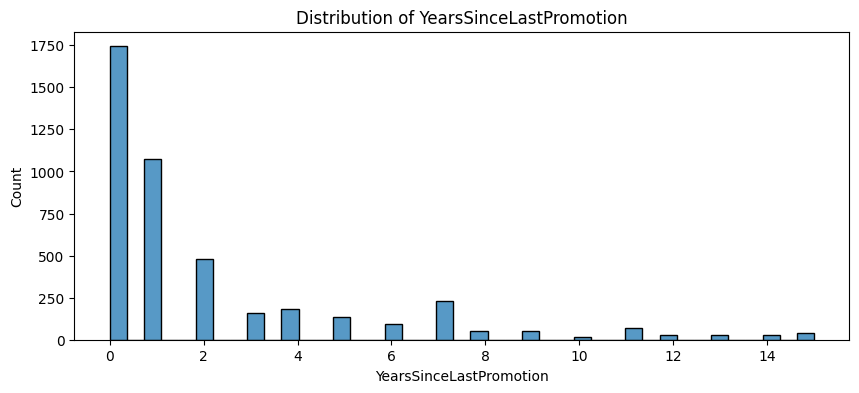

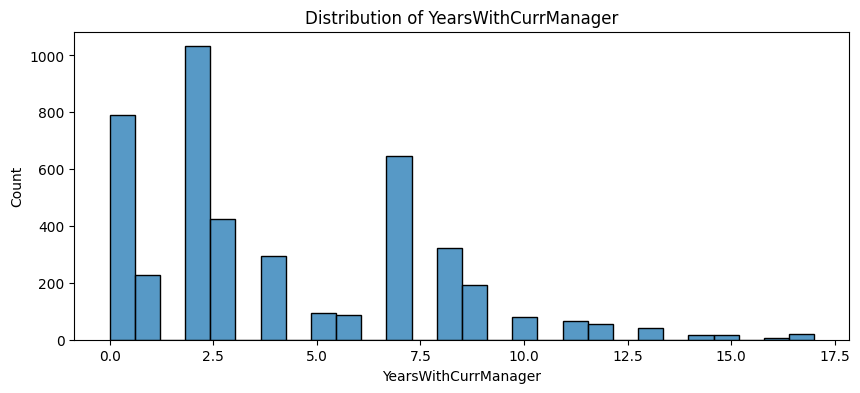

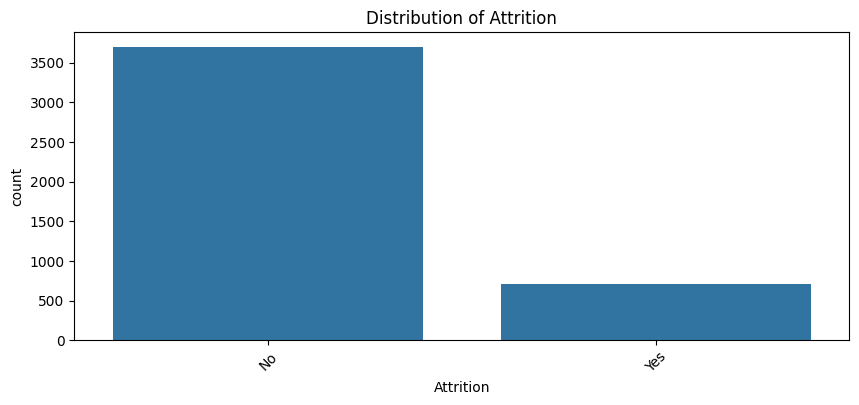

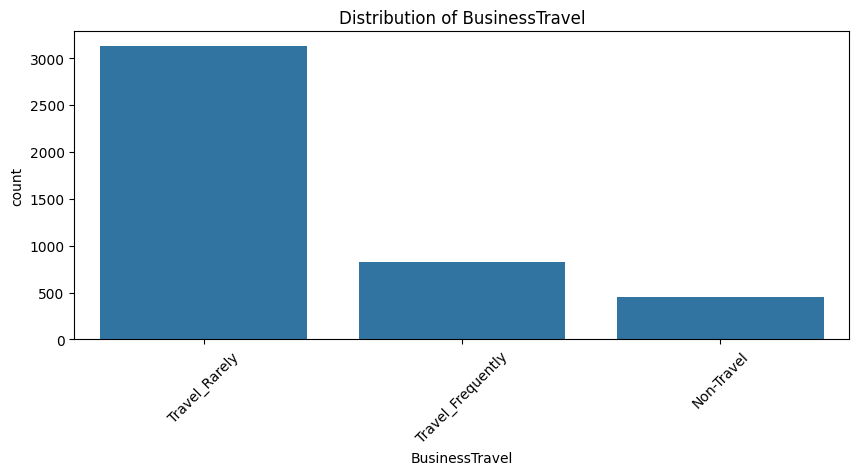

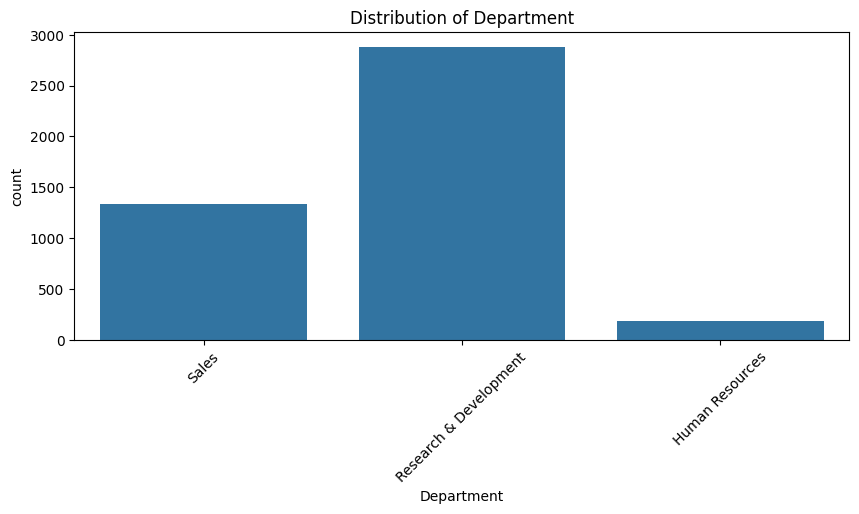

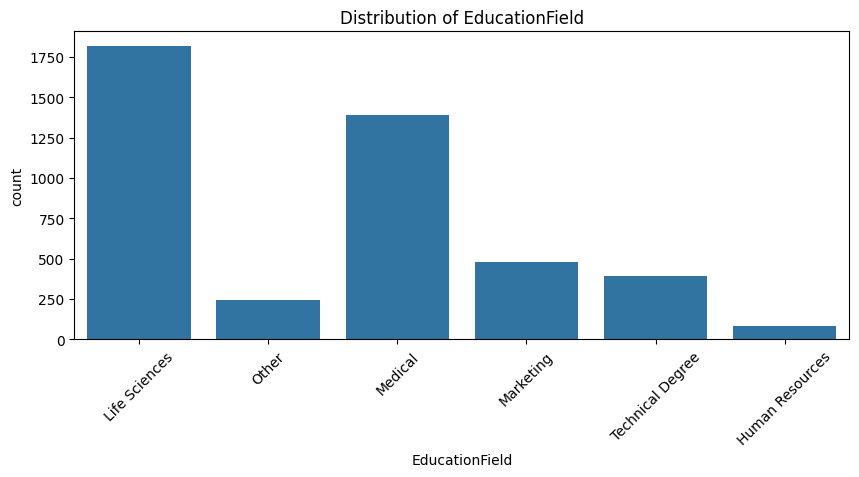

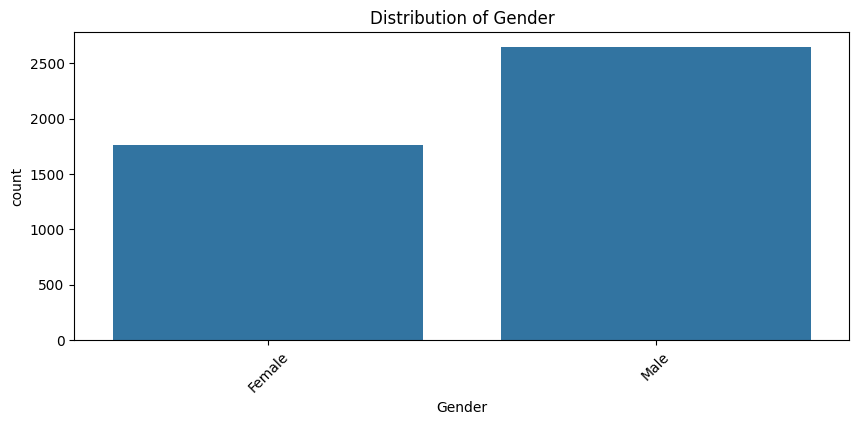

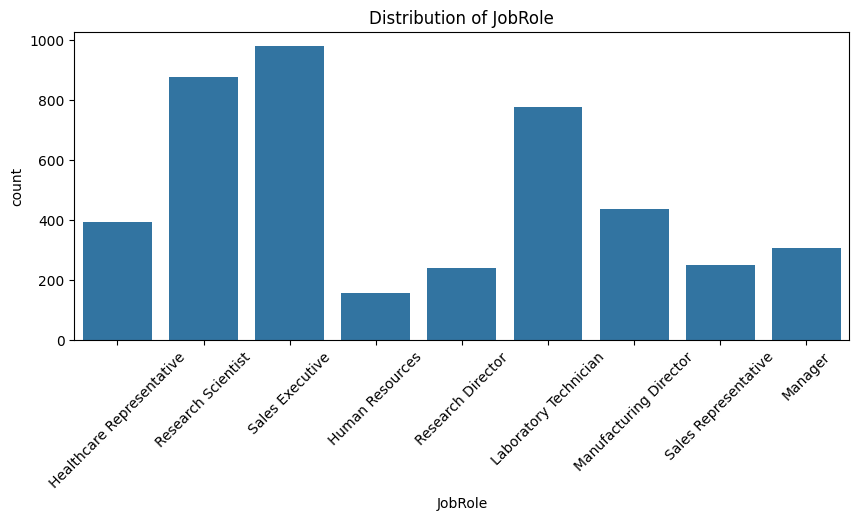

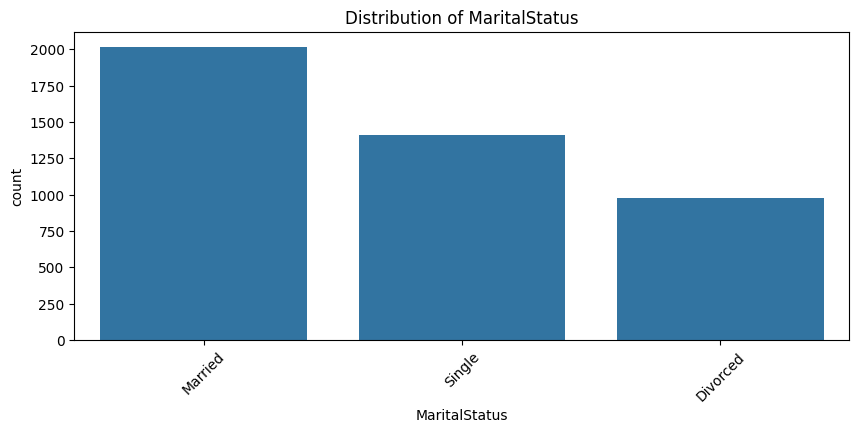

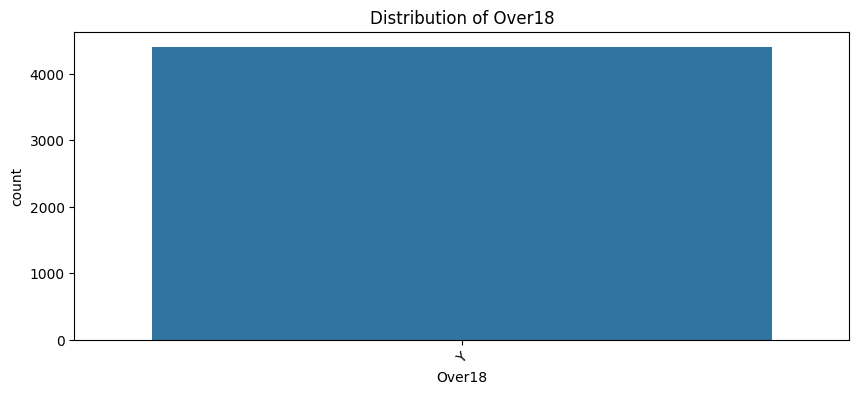

In [10]:
# Univariate analysis for numerical features
for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(x=general_data_updated[column])
    plt.title(f'Distribution of {column}')
    plt.show()
    
# Univariate analysis for categorical features
for column in categorical_columns:
    plt.figure(figsize=(10, 4))
    sns.countplot(x=general_data_updated[column])
    plt.title(f'Distribution of {column}')
    plt.xticks(rotation=45)
    plt.show()

##### Analyse bivariée

<Figure size 2000x400 with 0 Axes>

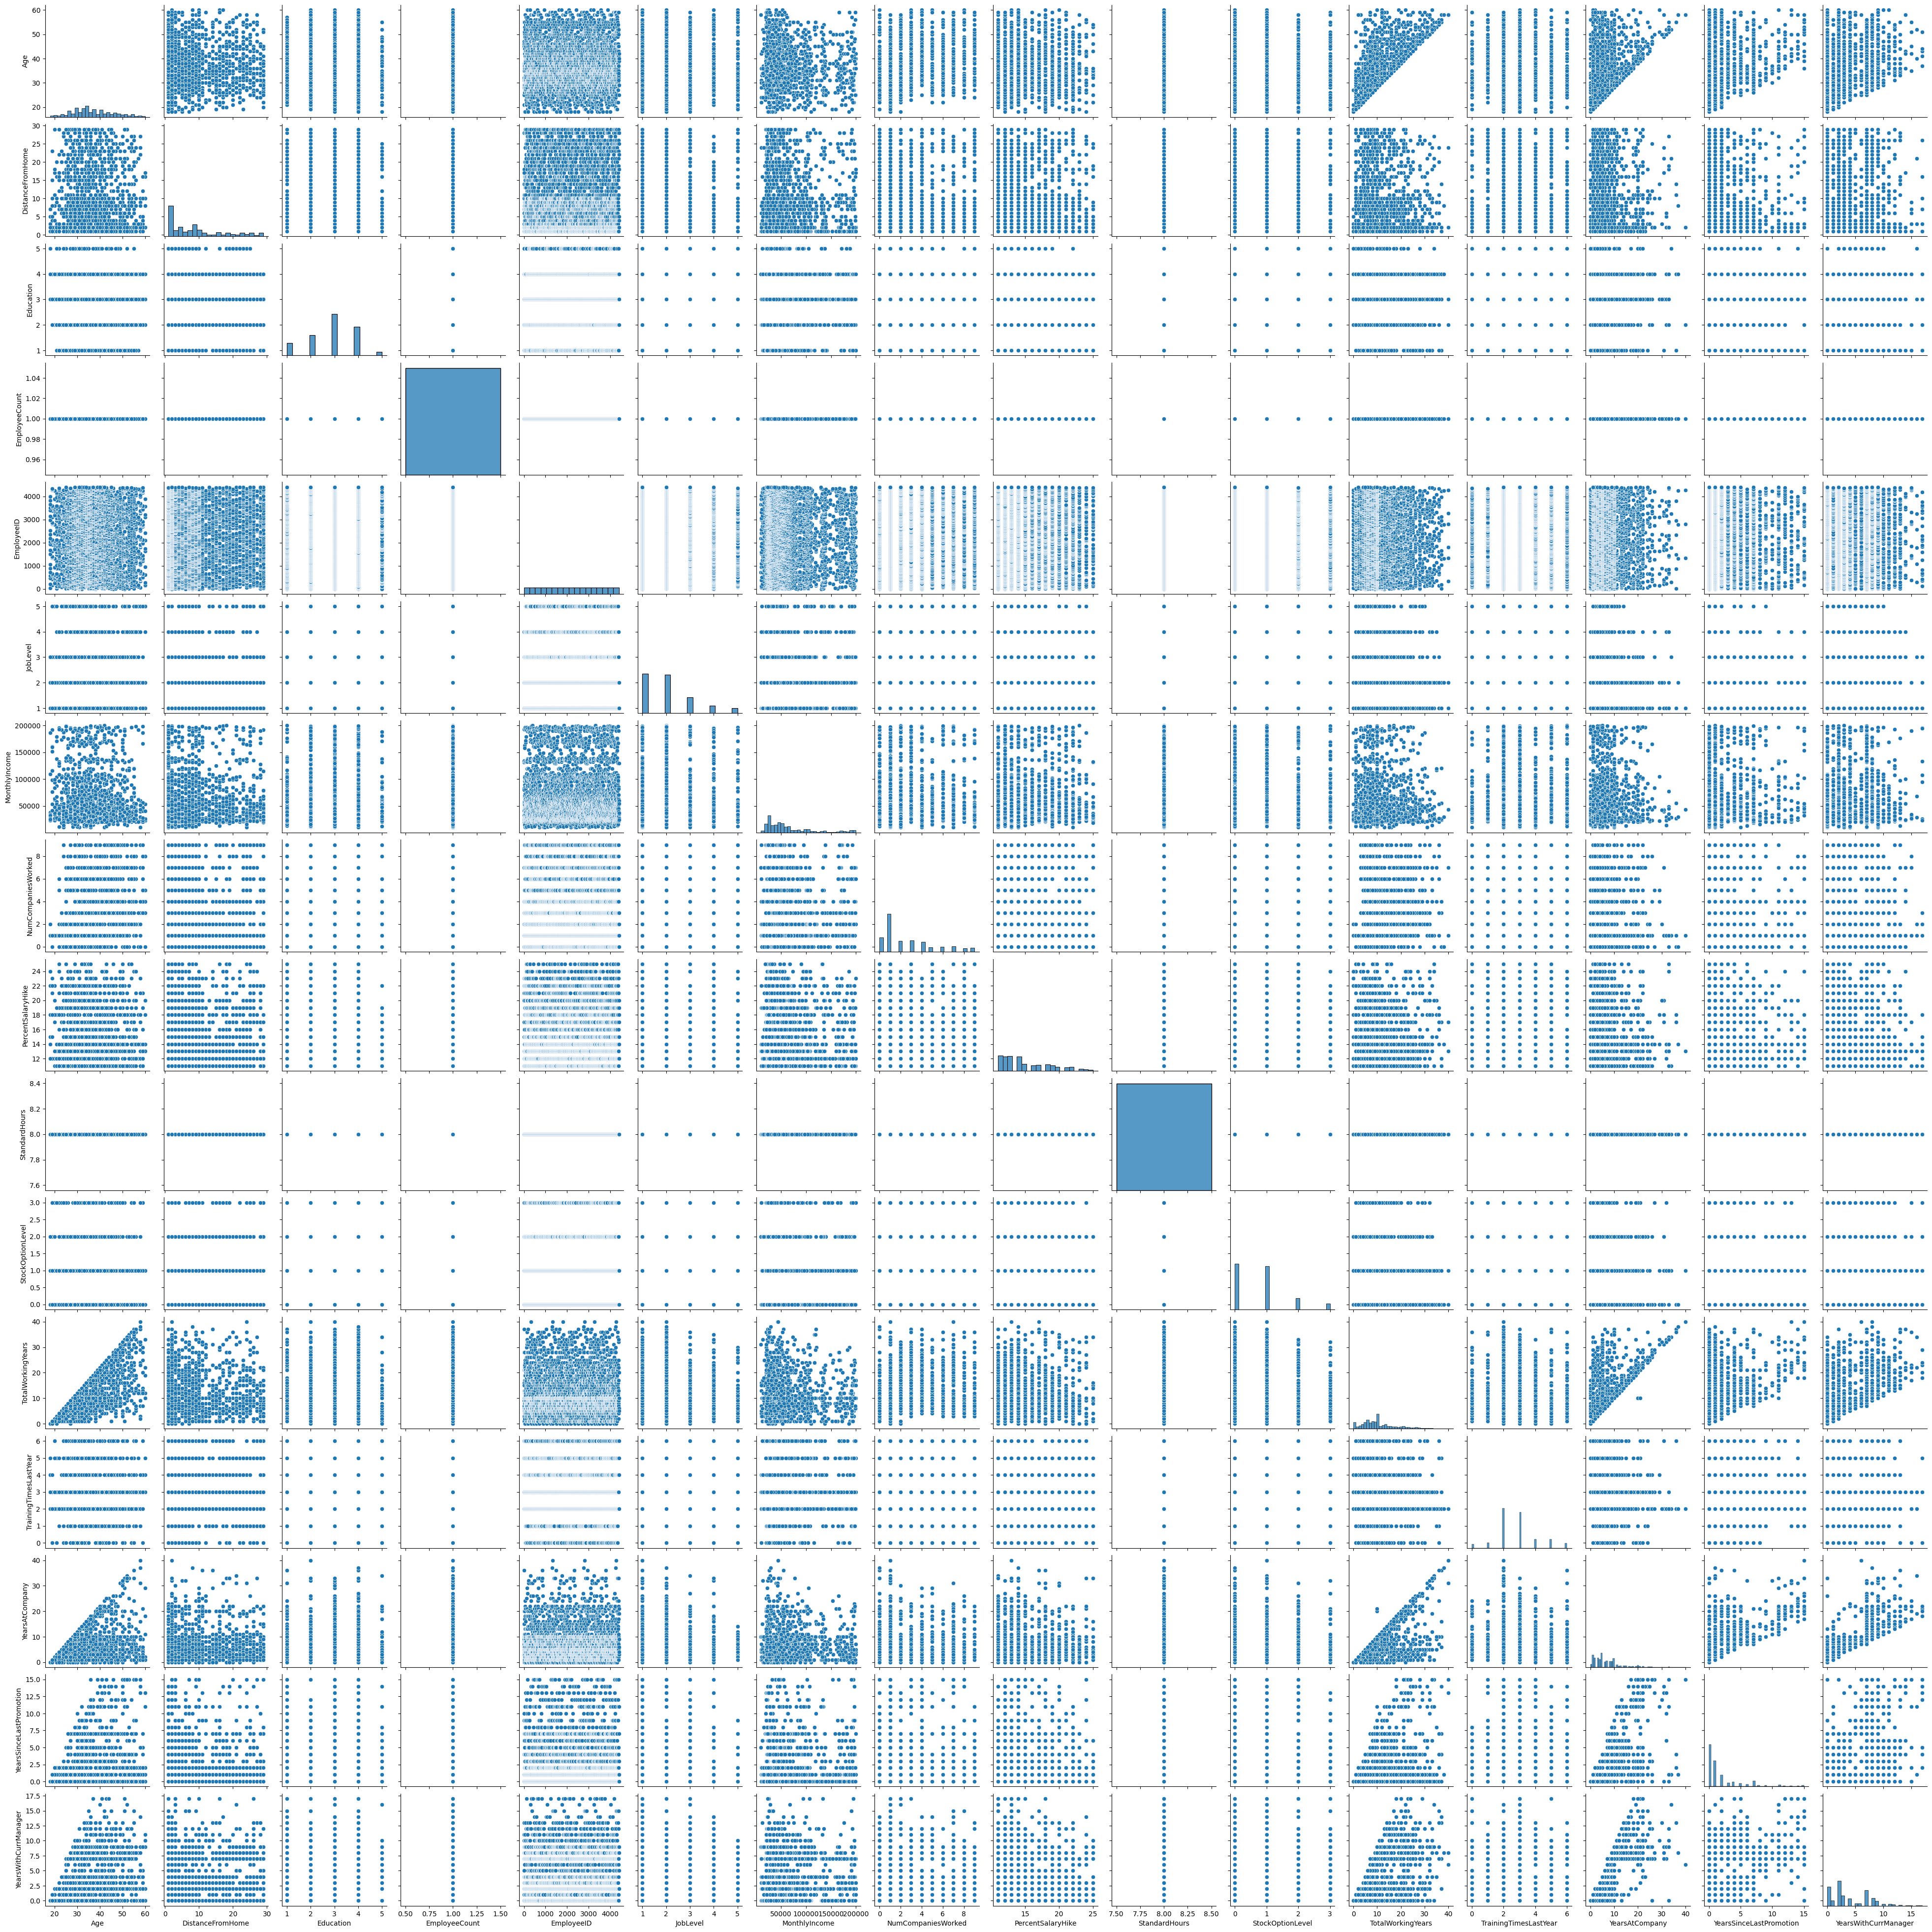

In [11]:
plt.figure(figsize=(20, 4))
sns.pairplot(general_data_updated[numerical_columns])
plt.show()

##### Analyse par Boite à moustache

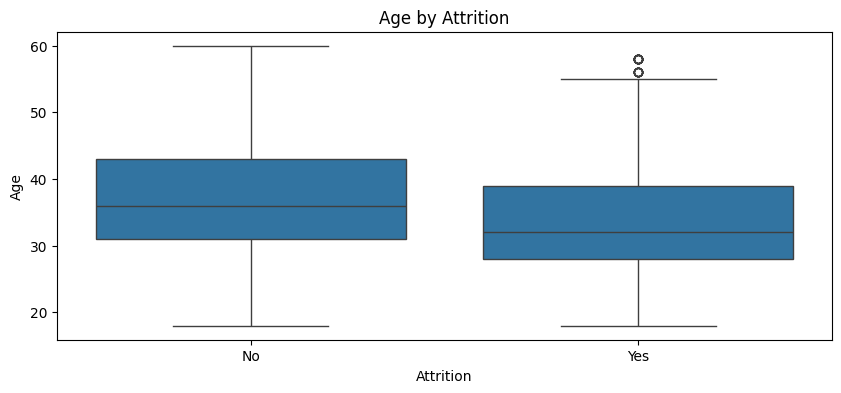

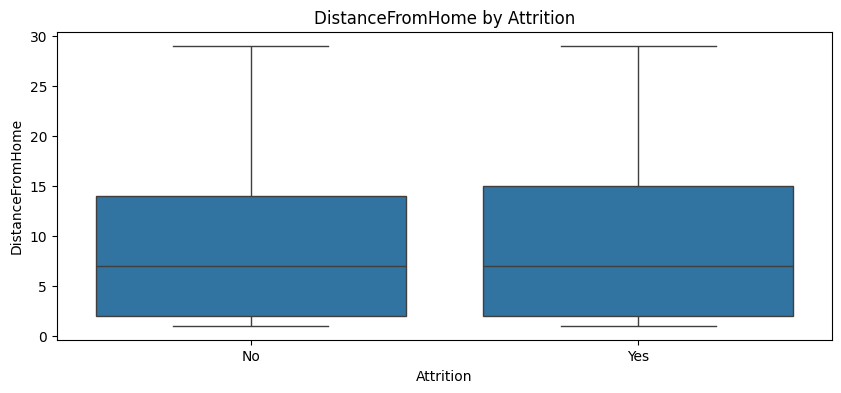

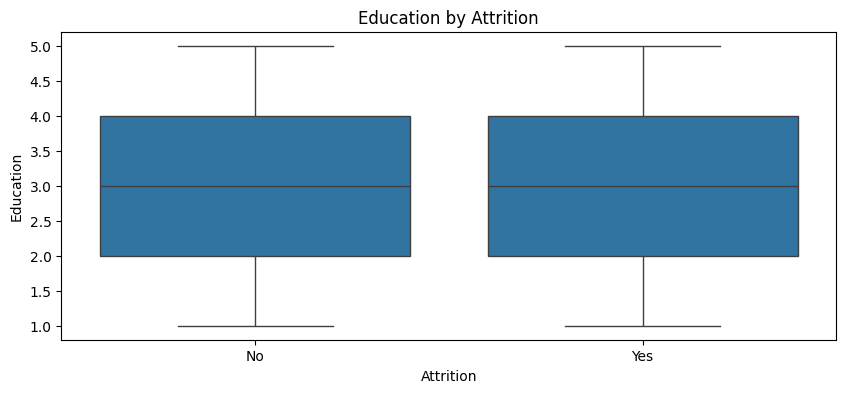

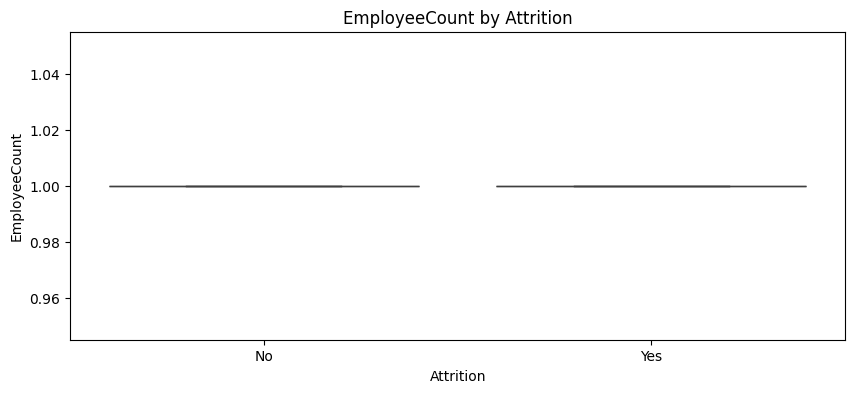

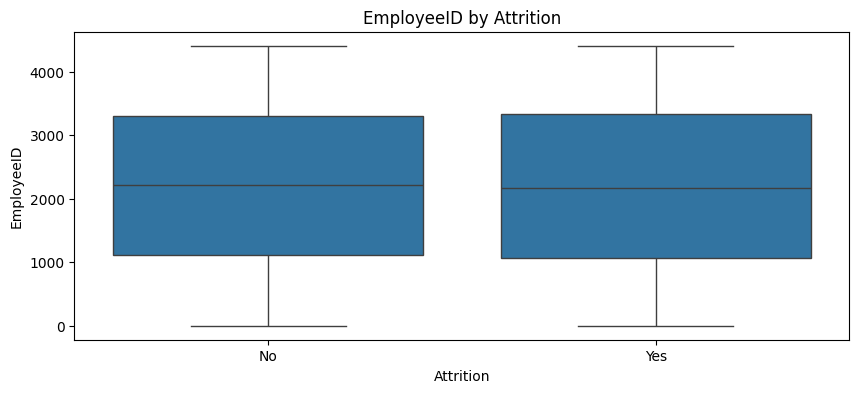

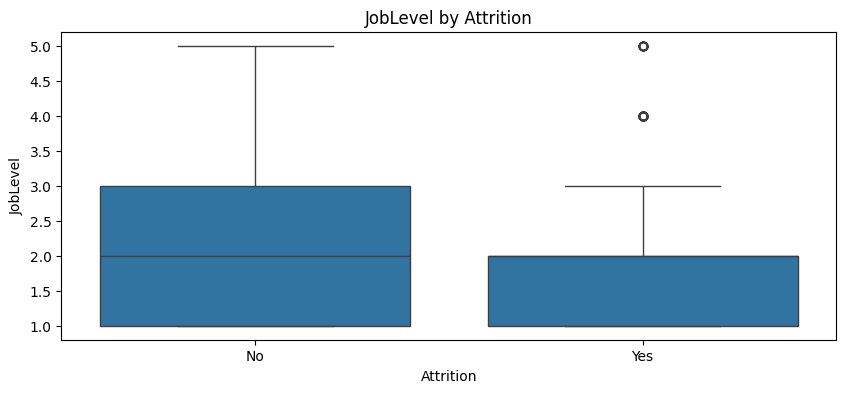

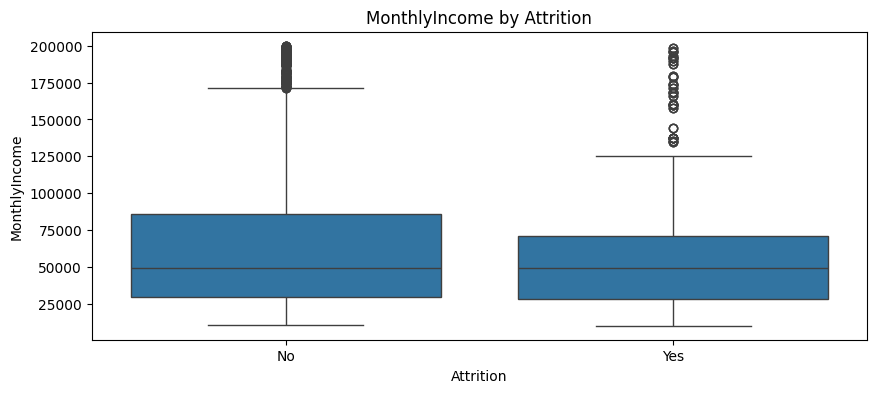

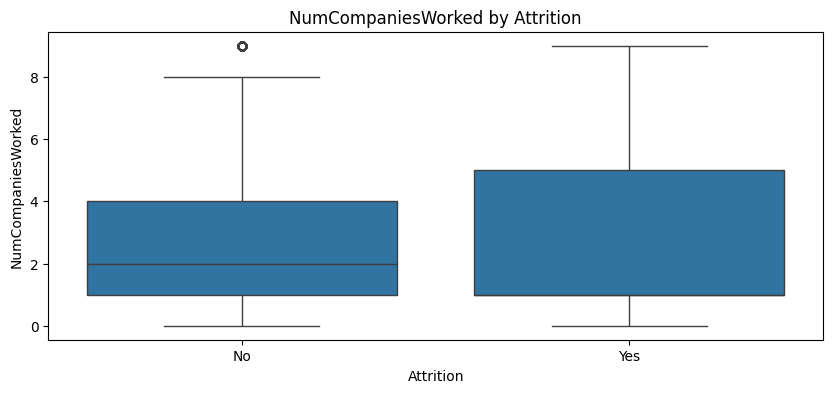

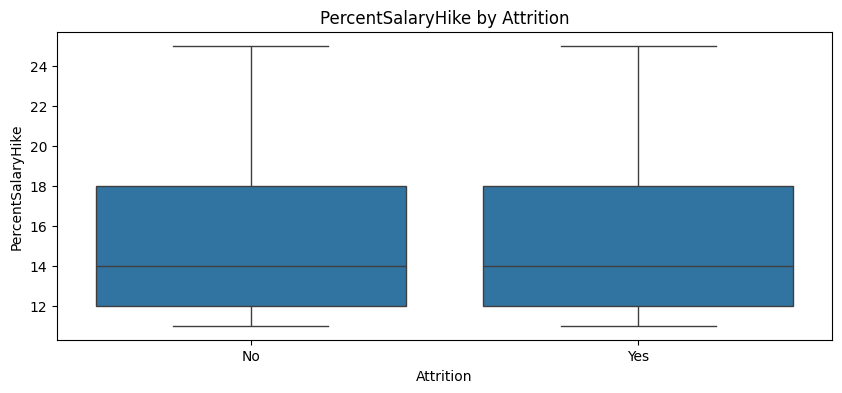

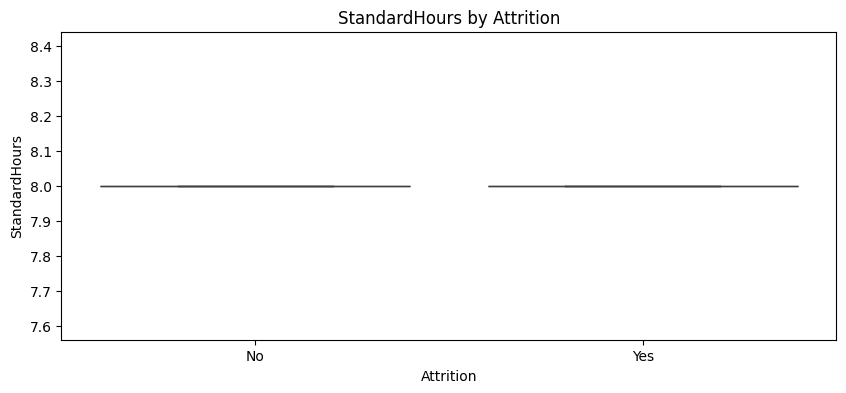

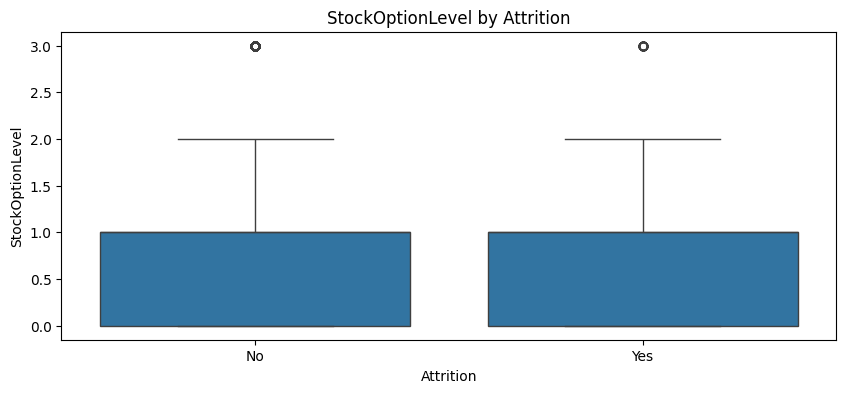

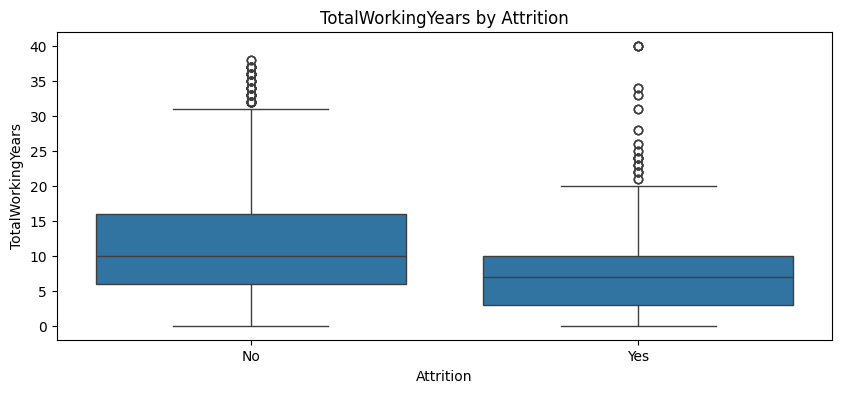

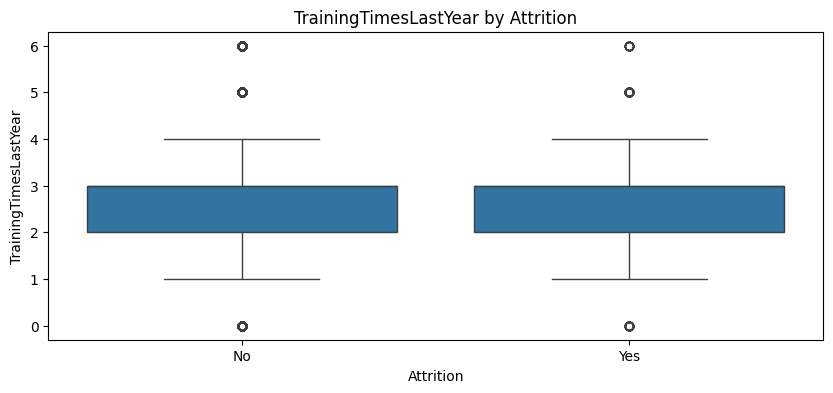

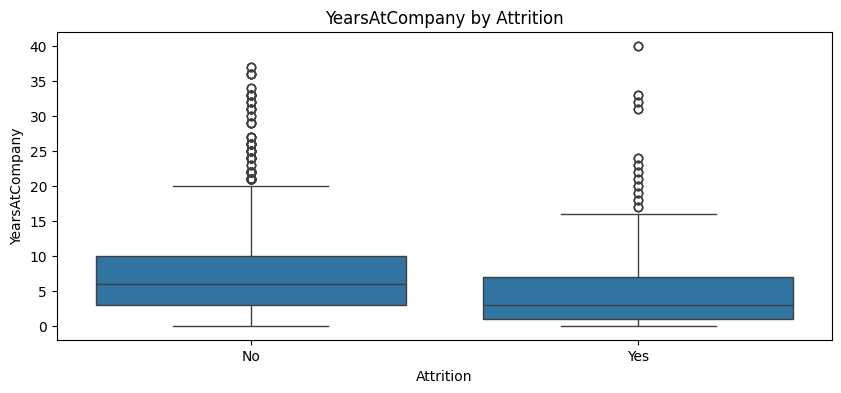

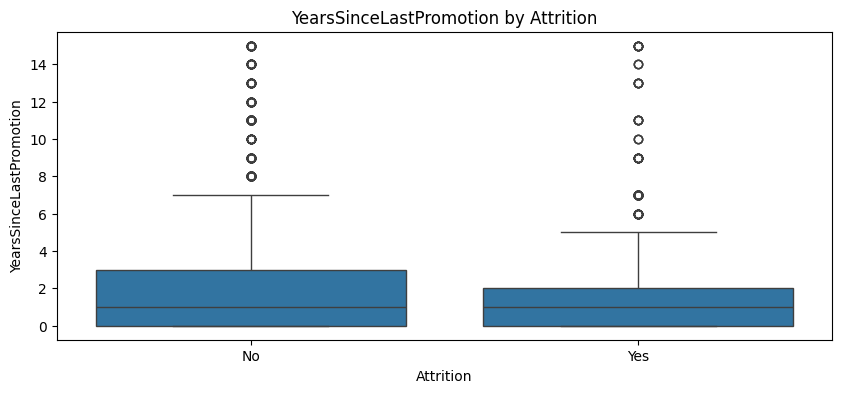

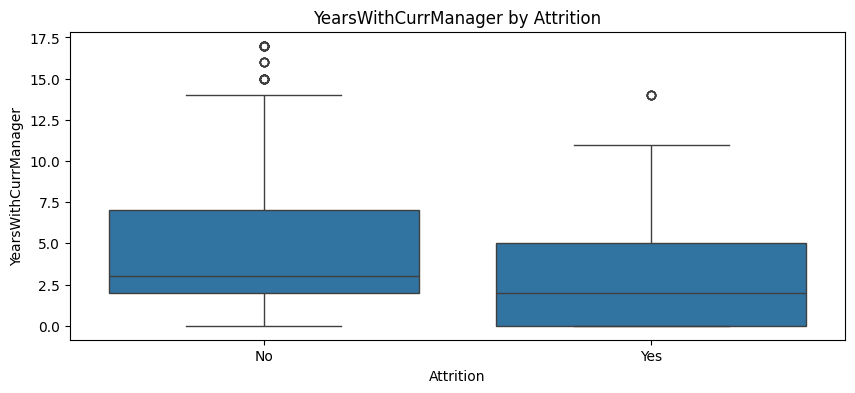

In [12]:
# Box plots for categorical vs numerical features
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=general_data_updated[categorical_column], y=general_data_updated[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

##### Analyse par matrice de correlation

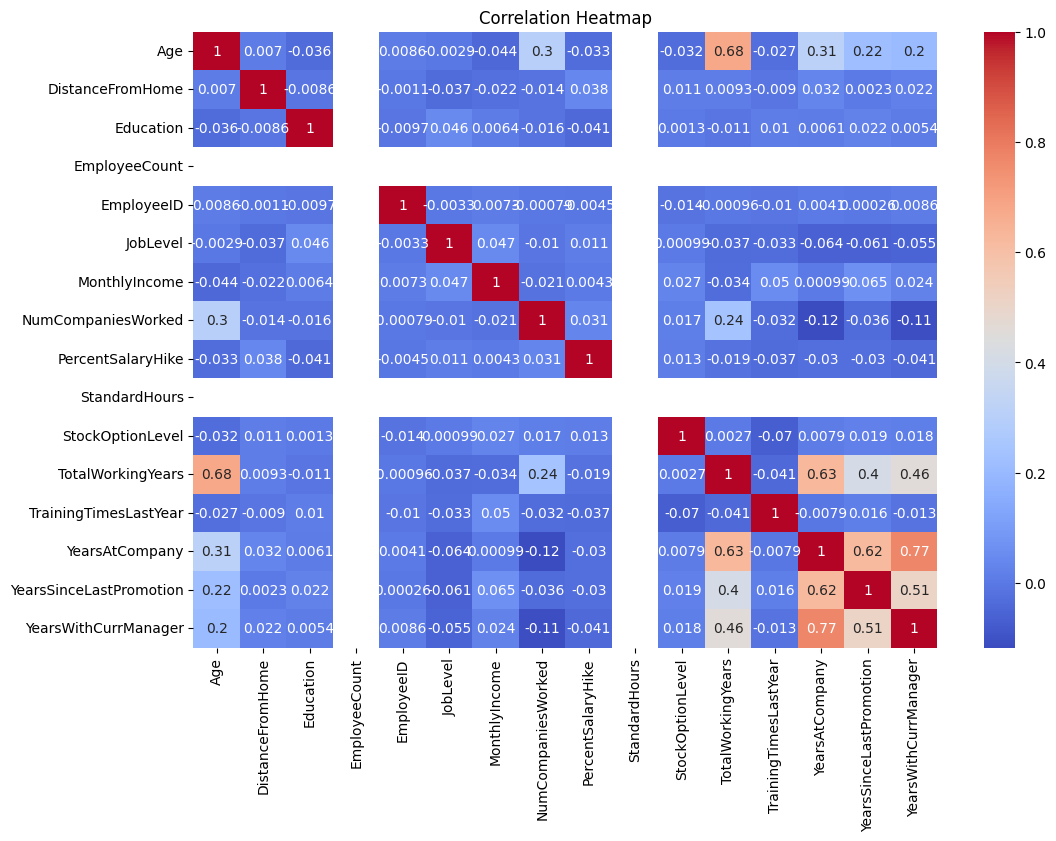

In [13]:
# Matrice de corrélation - Variables quantitatives continues uniquement
# Sélection des variables vraiment quantitatives (continues, pas catégorielles)
quantitative_columns = ['Age', 'DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 
                        'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear',
                        'YearsAtCompany', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

# Filtrer pour ne garder que les colonnes qui existent dans le dataset
quantitative_columns_available = [col for col in quantitative_columns if col in general_data_updated.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(general_data_updated[quantitative_columns_available].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap - Variables Quantitatives Continues')
plt.show()

#### Nettoyage des données

In [14]:
general_data_clean = general_data_updated.drop(["EmployeeCount", "StandardHours", "Over18"], axis=1)

general_data_clean.head()


,Age,DistanceFromHome,Education,EmployeeID,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,...,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus
0,51.0,6.0,2.0,1.0,1.0,131160.0,1.0,11.0,0.0,1.0,...,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Female,Healthcare Representative,Married
1,31.0,10.0,1.0,2.0,1.0,41890.0,0.0,23.0,1.0,6.0,...,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Single
2,32.0,17.0,4.0,3.0,4.0,193280.0,1.0,15.0,3.0,5.0,...,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Male,Sales Executive,Married
3,38.0,2.0,5.0,4.0,3.0,83210.0,3.0,11.0,3.0,13.0,...,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Male,Human Resources,Married
4,32.0,10.0,1.0,5.0,1.0,23420.0,4.0,12.0,2.0,9.0,...,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Male,Sales Executive,Single


### 2.2 Enquêtes de satisfaction des employées

En complément des données RH, deux enquêtes d'évaluation ont été menées en 2015 afin d'obtenir des retours sur la performance et la satisfaction des employés.

In [15]:
# Charger le dataset
employee_survey_data = pd.read_csv('Data_origin/employee_survey_data.csv')

# Afficher les premières lignes du dataset
employee_survey_data.head()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance
0,1,3.0,4.0,2.0
1,2,3.0,2.0,4.0
2,3,2.0,2.0,1.0
3,4,4.0,4.0,3.0
4,5,4.0,1.0,3.0


In [16]:
# Display basic information
employee_survey_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   EmployeeID               4410 non-null   int64  
 1   EnvironmentSatisfaction  4385 non-null   float64
 2   JobSatisfaction          4390 non-null   float64
 3   WorkLifeBalance          4372 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 137.9 KB


In [17]:
# Display summary statistics
employee_survey_data.describe()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance
count,4410.000000,4385.000000,4390.000000,4372.000000
mean,2205.500000,2.723603,2.728246,2.761436
std,1273.201673,1.092756,1.101253,0.706245
min,1.000000,1.000000,1.000000,1.000000
25%,1103.250000,2.000000,2.000000,2.000000
50%,2205.500000,3.000000,3.000000,3.000000
75%,3307.750000,4.000000,4.000000,3.000000
max,4410.000000,4.000000,4.000000,4.000000


In [18]:
# Detection des valeurs manquantes
employee_survey_data.isnull().sum()

EmployeeID                  0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
dtype: int64

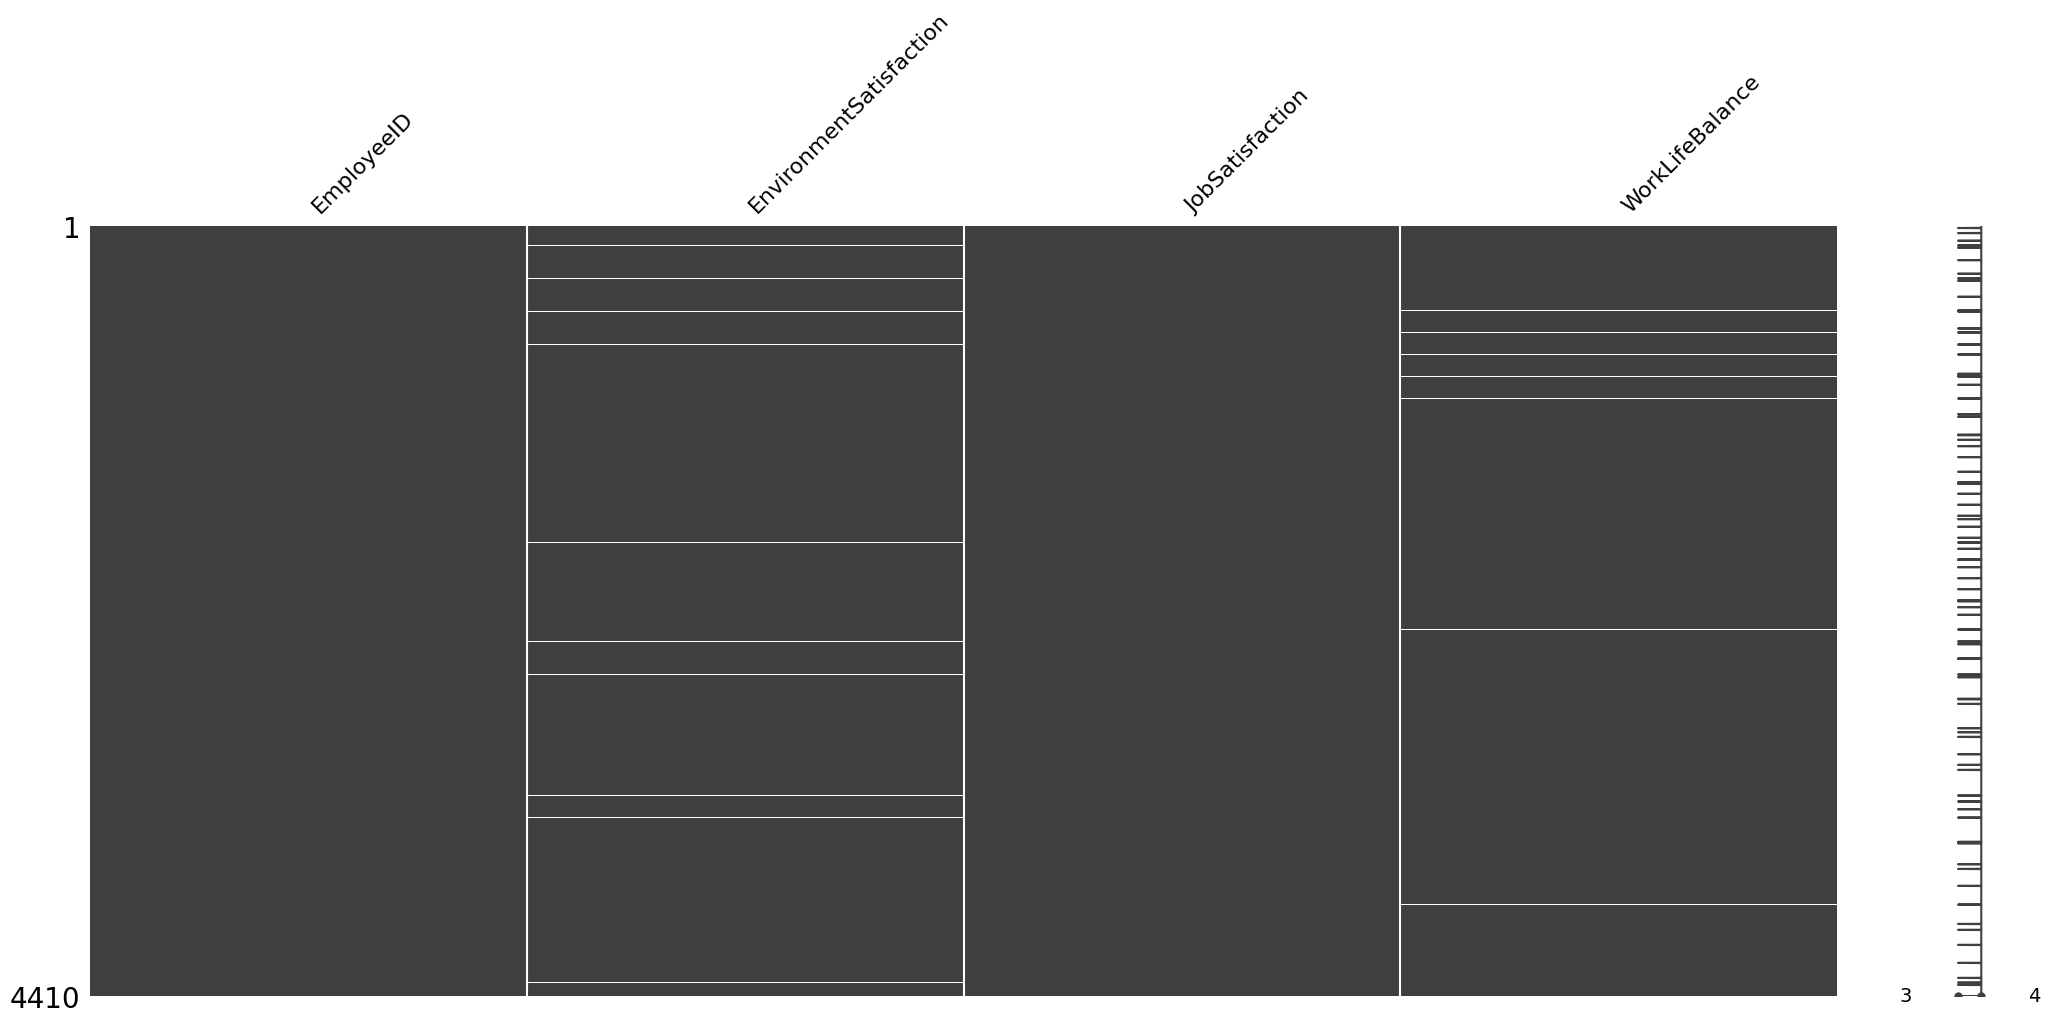

EmployeeID                 0
EnvironmentSatisfaction    0
JobSatisfaction            0
WorkLifeBalance            0
dtype: int64

In [19]:
# Visualisation des valeurs manquantes
msno.matrix(employee_survey_data)
plt.show()
employee_survey_data_updated = employee_survey_data.copy()

# Imputation des valeurs manquantes
imputer = SimpleImputer(strategy="median")

employee_survey_data_num = employee_survey_data_updated.select_dtypes(include=[np.number])
imputer.fit(employee_survey_data_num)

# Remplacement des valeurs manquantes
employee_survey_data_updated = pd.DataFrame(imputer.transform(employee_survey_data_num), columns=employee_survey_data_num.columns)

# Vérifier s'il reste des valeurs manquantes
employee_survey_data_updated.isnull().sum()

#### Fusion avec les données général

In [20]:
# Fusion des deux datasets
merged_general_employee_data = pd.merge(employee_survey_data_updated, general_data_clean, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_general_employee_data.head()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,...,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus
0,1.0,3.0,4.0,2.0,51.0,6.0,2.0,1.0,131160.0,1.0,...,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Female,Healthcare Representative,Married
1,2.0,3.0,2.0,4.0,31.0,10.0,1.0,1.0,41890.0,0.0,...,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Single
2,3.0,2.0,2.0,1.0,32.0,17.0,4.0,4.0,193280.0,1.0,...,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Male,Sales Executive,Married
3,4.0,4.0,4.0,3.0,38.0,2.0,5.0,3.0,83210.0,3.0,...,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Male,Human Resources,Married
4,5.0,4.0,1.0,3.0,32.0,10.0,1.0,1.0,23420.0,4.0,...,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Male,Sales Executive,Single


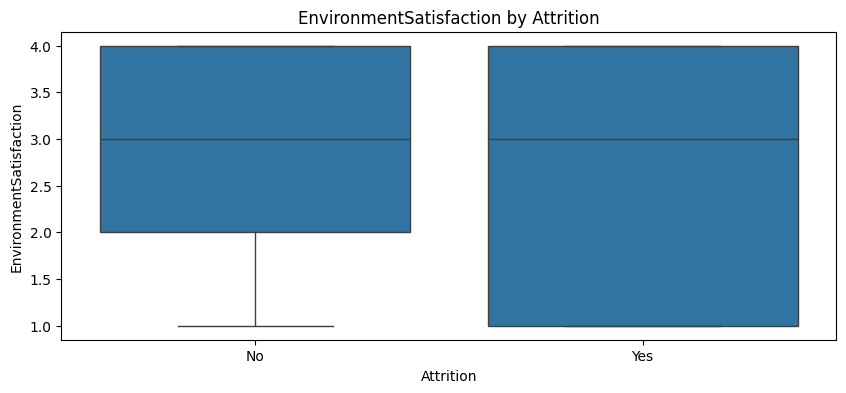

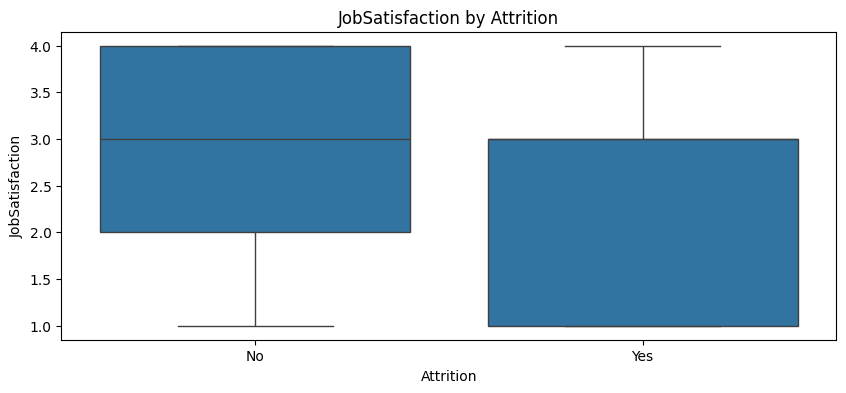

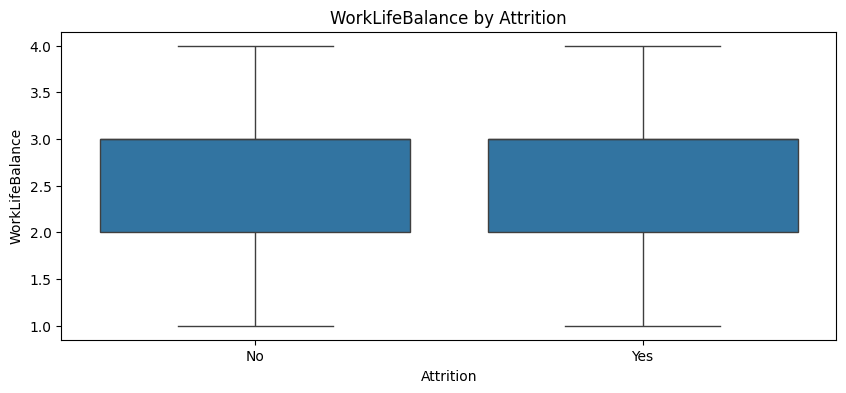

In [21]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_general_employee_data[categorical_column], y=merged_general_employee_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

### 2.3 Évaluation des managers

In [22]:
# Charger le dataset
manager_survey_data = pd.read_csv('Data_origin/manager_survey_data.csv')

# Afficher les premières lignes du dataset
manager_survey_data.head()

,EmployeeID,JobInvolvement,PerformanceRating
0,1,3,3
1,2,2,4
2,3,3,3
3,4,2,3
4,5,3,3


In [23]:
# Display basic information
manager_survey_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   EmployeeID         4410 non-null   int64
 1   JobInvolvement     4410 non-null   int64
 2   PerformanceRating  4410 non-null   int64
dtypes: int64(3)
memory usage: 103.5 KB


In [24]:
# Display summary statistics
manager_survey_data.describe()

,EmployeeID,JobInvolvement,PerformanceRating
count,4410.000000,4410.000000,4410.000000
mean,2205.500000,2.729932,3.153741
std,1273.201673,0.711400,0.360742
min,1.000000,1.000000,3.000000
25%,1103.250000,2.000000,3.000000
50%,2205.500000,3.000000,3.000000
75%,3307.750000,3.000000,3.000000
max,4410.000000,4.000000,4.000000


In [25]:
# Detection des valeurs manquantes
manager_survey_data.isnull().sum()

EmployeeID           0
JobInvolvement       0
PerformanceRating    0
dtype: int64

#### Fusion avec les données général

In [26]:
# Fusion des datasets
merged_general_employee_manager_data = pd.merge(manager_survey_data, merged_general_employee_data, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_general_employee_manager_data.head()

,EmployeeID,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,...,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus
0,1,3,3,3.0,4.0,2.0,51.0,6.0,2.0,1.0,...,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Female,Healthcare Representative,Married
1,2,2,4,3.0,2.0,4.0,31.0,10.0,1.0,1.0,...,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Single
2,3,3,3,2.0,2.0,1.0,32.0,17.0,4.0,4.0,...,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Male,Sales Executive,Married
3,4,2,3,4.0,4.0,3.0,38.0,2.0,5.0,3.0,...,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Male,Human Resources,Married
4,5,3,3,4.0,1.0,3.0,32.0,10.0,1.0,1.0,...,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Male,Sales Executive,Single


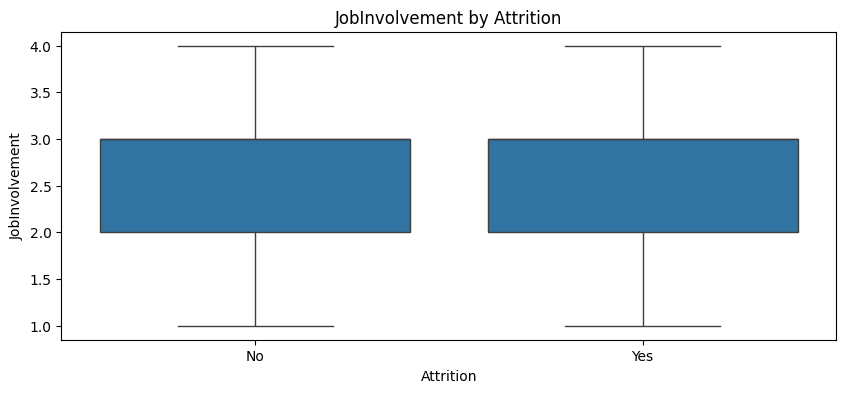

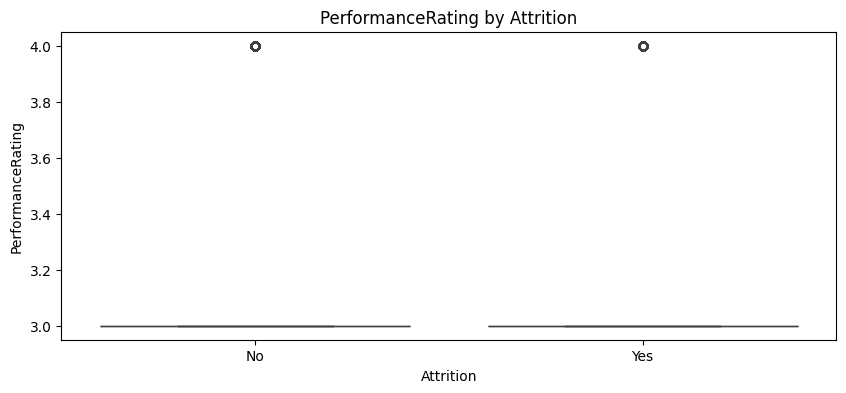

In [27]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["JobInvolvement", "PerformanceRating"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_general_employee_manager_data[categorical_column], y=merged_general_employee_manager_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

### 2.4 Données de temps (IN TIME & OUT TIME)

In [28]:
# Charger les datasets
in_time_data = pd.read_csv('Data_origin/in_time.csv')
out_time_data = pd.read_csv('Data_origin/out_time.csv')

# Afficher les premières lignes
print("IN TIME:")
display(in_time_data.head())
print("\nOUT TIME:")
display(out_time_data.head())

IN TIME:


,EmployeeID,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,1,NaN,2015-01-02 09:43:45,2015-01-05 10:08:48,2015-01-06 09:54:26,2015-01-07 09:34:31,2015-01-08 09:51:09,2015-01-09 10:09:25,2015-01-12 09:42:53,2015-01-13 10:13:06,...,NaN,2015-12-21 09:55:29,2015-12-22 10:04:06,2015-12-23 10:14:27,2015-12-24 10:11:35,NaN,2015-12-28 10:13:41,2015-12-29 10:03:36,2015-12-30 09:54:12,2015-12-31 10:12:44
1,2,NaN,2015-01-02 10:15:44,2015-01-05 10:21:05,NaN,2015-01-07 09:45:17,2015-01-08 10:09:04,2015-01-09 09:43:26,2015-01-12 10:00:07,2015-01-13 10:43:29,...,2015-12-18 10:37:17,2015-12-21 09:49:02,2015-12-22 10:33:51,2015-12-23 10:12:10,NaN,NaN,2015-12-28 09:31:45,2015-12-29 09:55:49,2015-12-30 10:32:25,2015-12-31 09:27:20
2,3,NaN,2015-01-02 10:17:41,2015-01-05 09:50:50,2015-01-06 10:14:13,2015-01-07 09:47:27,2015-01-08 10:03:40,2015-01-09 10:05:49,2015-01-12 10:03:47,2015-01-13 10:21:26,...,2015-12-18 10:15:14,2015-12-21 10:10:28,2015-12-22 09:44:44,2015-12-23 10:15:54,2015-12-24 10:07:26,NaN,2015-12-28 09:42:05,2015-12-29 09:43:36,2015-12-30 09:34:05,2015-12-31 10:28:39
3,4,NaN,2015-01-02 10:05:06,2015-01-05 09:56:32,2015-01-06 10:11:07,2015-01-07 09:37:30,2015-01-08 10:02:08,2015-01-09 10:08:12,2015-01-12 10:13:42,2015-01-13 09:53:22,...,2015-12-18 10:17:38,2015-12-21 09:58:21,2015-12-22 10:04:25,2015-12-23 10:11:46,2015-12-24 09:43:15,NaN,2015-12-28 09:52:44,2015-12-29 09:33:16,2015-12-30 10:18:12,2015-12-31 10:01:15
4,5,NaN,2015-01-02 10:28:17,2015-01-05 09:49:58,2015-01-06 09:45:28,2015-01-07 09:49:37,2015-01-08 10:19:44,2015-01-09 10:00:50,2015-01-12 10:29:27,2015-01-13 09:59:32,...,2015-12-18 09:58:35,2015-12-21 10:03:41,2015-12-22 10:10:30,2015-12-23 10:13:36,2015-12-24 09:44:24,NaN,2015-12-28 10:05:15,2015-12-29 10:30:53,2015-12-30 09:18:21,2015-12-31 09:41:09



OUT TIME:


,EmployeeID,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,1,NaN,2015-01-02 16:56:15,2015-01-05 17:20:11,2015-01-06 17:19:05,2015-01-07 16:34:55,2015-01-08 17:08:32,2015-01-09 17:38:29,2015-01-12 16:58:39,2015-01-13 18:02:58,...,NaN,2015-12-21 17:15:50,2015-12-22 17:27:51,2015-12-23 16:44:44,2015-12-24 17:47:22,NaN,2015-12-28 18:00:07,2015-12-29 17:22:30,2015-12-30 17:40:56,2015-12-31 17:17:33
1,2,NaN,2015-01-02 18:22:17,2015-01-05 17:48:22,NaN,2015-01-07 17:09:06,2015-01-08 17:34:04,2015-01-09 16:52:29,2015-01-12 17:36:48,2015-01-13 18:00:13,...,2015-12-18 18:31:28,2015-12-21 17:34:16,2015-12-22 18:16:35,2015-12-23 17:38:18,NaN,NaN,2015-12-28 17:08:38,2015-12-29 17:54:46,2015-12-30 18:31:35,2015-12-31 17:40:58
2,3,NaN,2015-01-02 16:59:14,2015-01-05 17:06:46,2015-01-06 16:38:32,2015-01-07 16:33:21,2015-01-08 17:24:22,2015-01-09 16:57:30,2015-01-12 17:28:54,2015-01-13 17:21:25,...,2015-12-18 17:02:23,2015-12-21 17:20:17,2015-12-22 16:32:50,2015-12-23 16:59:43,2015-12-24 16:58:25,NaN,2015-12-28 16:43:31,2015-12-29 17:09:56,2015-12-30 17:06:25,2015-12-31 17:15:50
3,4,NaN,2015-01-02 17:25:24,2015-01-05 17:14:03,2015-01-06 17:07:42,2015-01-07 16:32:40,2015-01-08 16:53:11,2015-01-09 17:19:47,2015-01-12 17:13:37,2015-01-13 17:11:45,...,2015-12-18 17:55:23,2015-12-21 16:49:09,2015-12-22 17:24:00,2015-12-23 17:36:35,2015-12-24 16:48:21,NaN,2015-12-28 17:19:34,2015-12-29 16:58:16,2015-12-30 17:40:11,2015-12-31 17:09:14
4,5,NaN,2015-01-02 18:31:37,2015-01-05 17:49:15,2015-01-06 17:26:25,2015-01-07 17:37:59,2015-01-08 17:59:28,2015-01-09 17:44:08,2015-01-12 18:51:21,2015-01-13 18:14:58,...,2015-12-18 17:52:48,2015-12-21 17:43:35,2015-12-22 18:07:57,2015-12-23 18:00:49,2015-12-24 17:59:22,NaN,2015-12-28 17:44:59,2015-12-29 18:47:00,2015-12-30 17:15:33,2015-12-31 17:42:14


In [29]:
# Conversion en datetime
in_time_data[in_time_data.drop('EmployeeID', axis=1).columns] = in_time_data[in_time_data.drop('EmployeeID', axis=1).columns].apply(pd.to_datetime)
out_time_data[out_time_data.drop('EmployeeID', axis=1).columns] = out_time_data[out_time_data.drop('EmployeeID', axis=1).columns].apply(pd.to_datetime)

print("Types après conversion:")
in_time_data.info()

Types après conversion:
<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, EmployeeID to 2015-12-31
dtypes: datetime64[s](12), datetime64[us](249), int64(1)
memory usage: 8.8 MB


#### Calcul du temps de travail moyen

In [30]:
temp_time = in_time_data.copy()
temp_time = out_time_data.drop("EmployeeID", axis=1) - temp_time.drop("EmployeeID", axis=1)

temp_time.head()

,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,2015-01-14,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,NaT,0 days 07:12:30,0 days 07:11:23,0 days 07:24:39,0 days 07:00:24,0 days 07:17:23,0 days 07:29:04,0 days 07:15:46,0 days 07:49:52,NaT,...,NaT,0 days 07:20:21,0 days 07:23:45,0 days 06:30:17,0 days 07:35:47,NaT,0 days 07:46:26,0 days 07:18:54,0 days 07:46:44,0 days 07:04:49
1,NaT,0 days 08:06:33,0 days 07:27:17,NaT,0 days 07:23:49,0 days 07:25:00,0 days 07:09:03,0 days 07:36:41,0 days 07:16:44,NaT,...,0 days 07:54:11,0 days 07:45:14,0 days 07:42:44,0 days 07:26:08,NaT,NaT,0 days 07:36:53,0 days 07:58:57,0 days 07:59:10,0 days 08:13:38
2,NaT,0 days 06:41:33,0 days 07:15:56,0 days 06:24:19,0 days 06:45:54,0 days 07:20:42,0 days 06:51:41,0 days 07:25:07,0 days 06:59:59,NaT,...,0 days 06:47:09,0 days 07:09:49,0 days 06:48:06,0 days 06:43:49,0 days 06:50:59,NaT,0 days 07:01:26,0 days 07:26:20,0 days 07:32:20,0 days 06:47:11
3,NaT,0 days 07:20:18,0 days 07:17:31,0 days 06:56:35,0 days 06:55:10,0 days 06:51:03,0 days 07:11:35,0 days 06:59:55,0 days 07:18:23,NaT,...,0 days 07:37:45,0 days 06:50:48,0 days 07:19:35,0 days 07:24:49,0 days 07:05:06,NaT,0 days 07:26:50,0 days 07:25:00,0 days 07:21:59,0 days 07:07:59
4,NaT,0 days 08:03:20,0 days 07:59:17,0 days 07:40:57,0 days 07:48:22,0 days 07:39:44,0 days 07:43:18,0 days 08:21:54,0 days 08:15:26,NaT,...,0 days 07:54:13,0 days 07:39:54,0 days 07:57:27,0 days 07:47:13,0 days 08:14:58,NaT,0 days 07:39:44,0 days 08:16:07,0 days 07:57:12,0 days 08:01:05


In [31]:
final_time = temp_time.copy()

final_time["avg_working_time"] = temp_time.mean(axis=1)
final_time["EmployeeID"] = in_time_data["EmployeeID"]

final_time["avg_working_time_seconds"] = final_time['avg_working_time'].dt.seconds

final_time.head()

,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,2015-01-14,...,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31,avg_working_time,EmployeeID,avg_working_time_seconds
0,NaT,0 days 07:12:30,0 days 07:11:23,0 days 07:24:39,0 days 07:00:24,0 days 07:17:23,0 days 07:29:04,0 days 07:15:46,0 days 07:49:52,NaT,...,0 days 06:30:17,0 days 07:35:47,NaT,0 days 07:46:26,0 days 07:18:54,0 days 07:46:44,0 days 07:04:49,0 days 07:22:25.142241,1,26545
1,NaT,0 days 08:06:33,0 days 07:27:17,NaT,0 days 07:23:49,0 days 07:25:00,0 days 07:09:03,0 days 07:36:41,0 days 07:16:44,NaT,...,0 days 07:26:08,NaT,NaT,0 days 07:36:53,0 days 07:58:57,0 days 07:59:10,0 days 08:13:38,0 days 07:43:08.288135,2,27788
2,NaT,0 days 06:41:33,0 days 07:15:56,0 days 06:24:19,0 days 06:45:54,0 days 07:20:42,0 days 06:51:41,0 days 07:25:07,0 days 06:59:59,NaT,...,0 days 06:43:49,0 days 06:50:59,NaT,0 days 07:01:26,0 days 07:26:20,0 days 07:32:20,0 days 06:47:11,0 days 07:00:47.665289,3,25247
3,NaT,0 days 07:20:18,0 days 07:17:31,0 days 06:56:35,0 days 06:55:10,0 days 06:51:03,0 days 07:11:35,0 days 06:59:55,0 days 07:18:23,NaT,...,0 days 07:24:49,0 days 07:05:06,NaT,0 days 07:26:50,0 days 07:25:00,0 days 07:21:59,0 days 07:07:59,0 days 07:11:37.242553,4,25897
4,NaT,0 days 08:03:20,0 days 07:59:17,0 days 07:40:57,0 days 07:48:22,0 days 07:39:44,0 days 07:43:18,0 days 08:21:54,0 days 08:15:26,NaT,...,0 days 07:47:13,0 days 08:14:58,NaT,0 days 07:39:44,0 days 08:16:07,0 days 07:57:12,0 days 08:01:05,0 days 08:00:22.228571,5,28822


#### Fusion avec les données générales

In [32]:
# Fusion des datasets
merged_global_data = pd.merge(final_time[["EmployeeID", "avg_working_time_seconds"]], merged_general_employee_manager_data, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_global_data.head()

,EmployeeID,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,...,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus
0,1,26545,3,3,3.0,4.0,2.0,51.0,6.0,2.0,...,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Female,Healthcare Representative,Married
1,2,27788,2,4,3.0,2.0,4.0,31.0,10.0,1.0,...,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Single
2,3,25247,3,3,2.0,2.0,1.0,32.0,17.0,4.0,...,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Male,Sales Executive,Married
3,4,25897,2,3,4.0,4.0,3.0,38.0,2.0,5.0,...,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Male,Human Resources,Married
4,5,28822,3,3,4.0,1.0,3.0,32.0,10.0,1.0,...,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Male,Sales Executive,Single


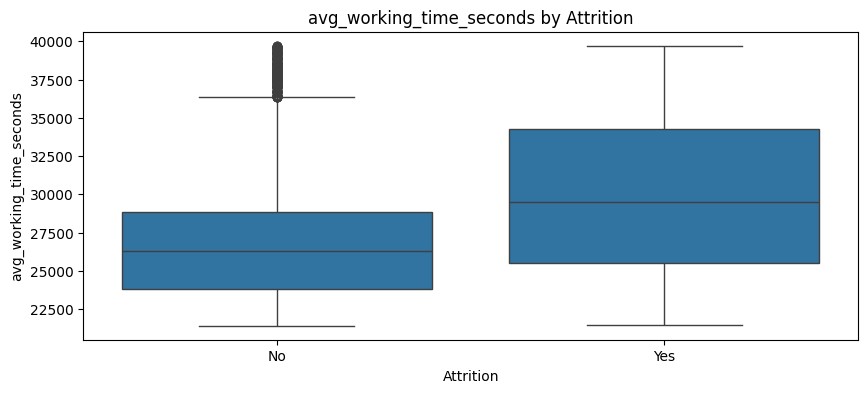

In [33]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["avg_working_time_seconds"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_global_data[categorical_column], y=merged_global_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

## 3. Analyse globale des données fusionnées

### Analyse bivariée

<Figure size 2000x400 with 0 Axes>

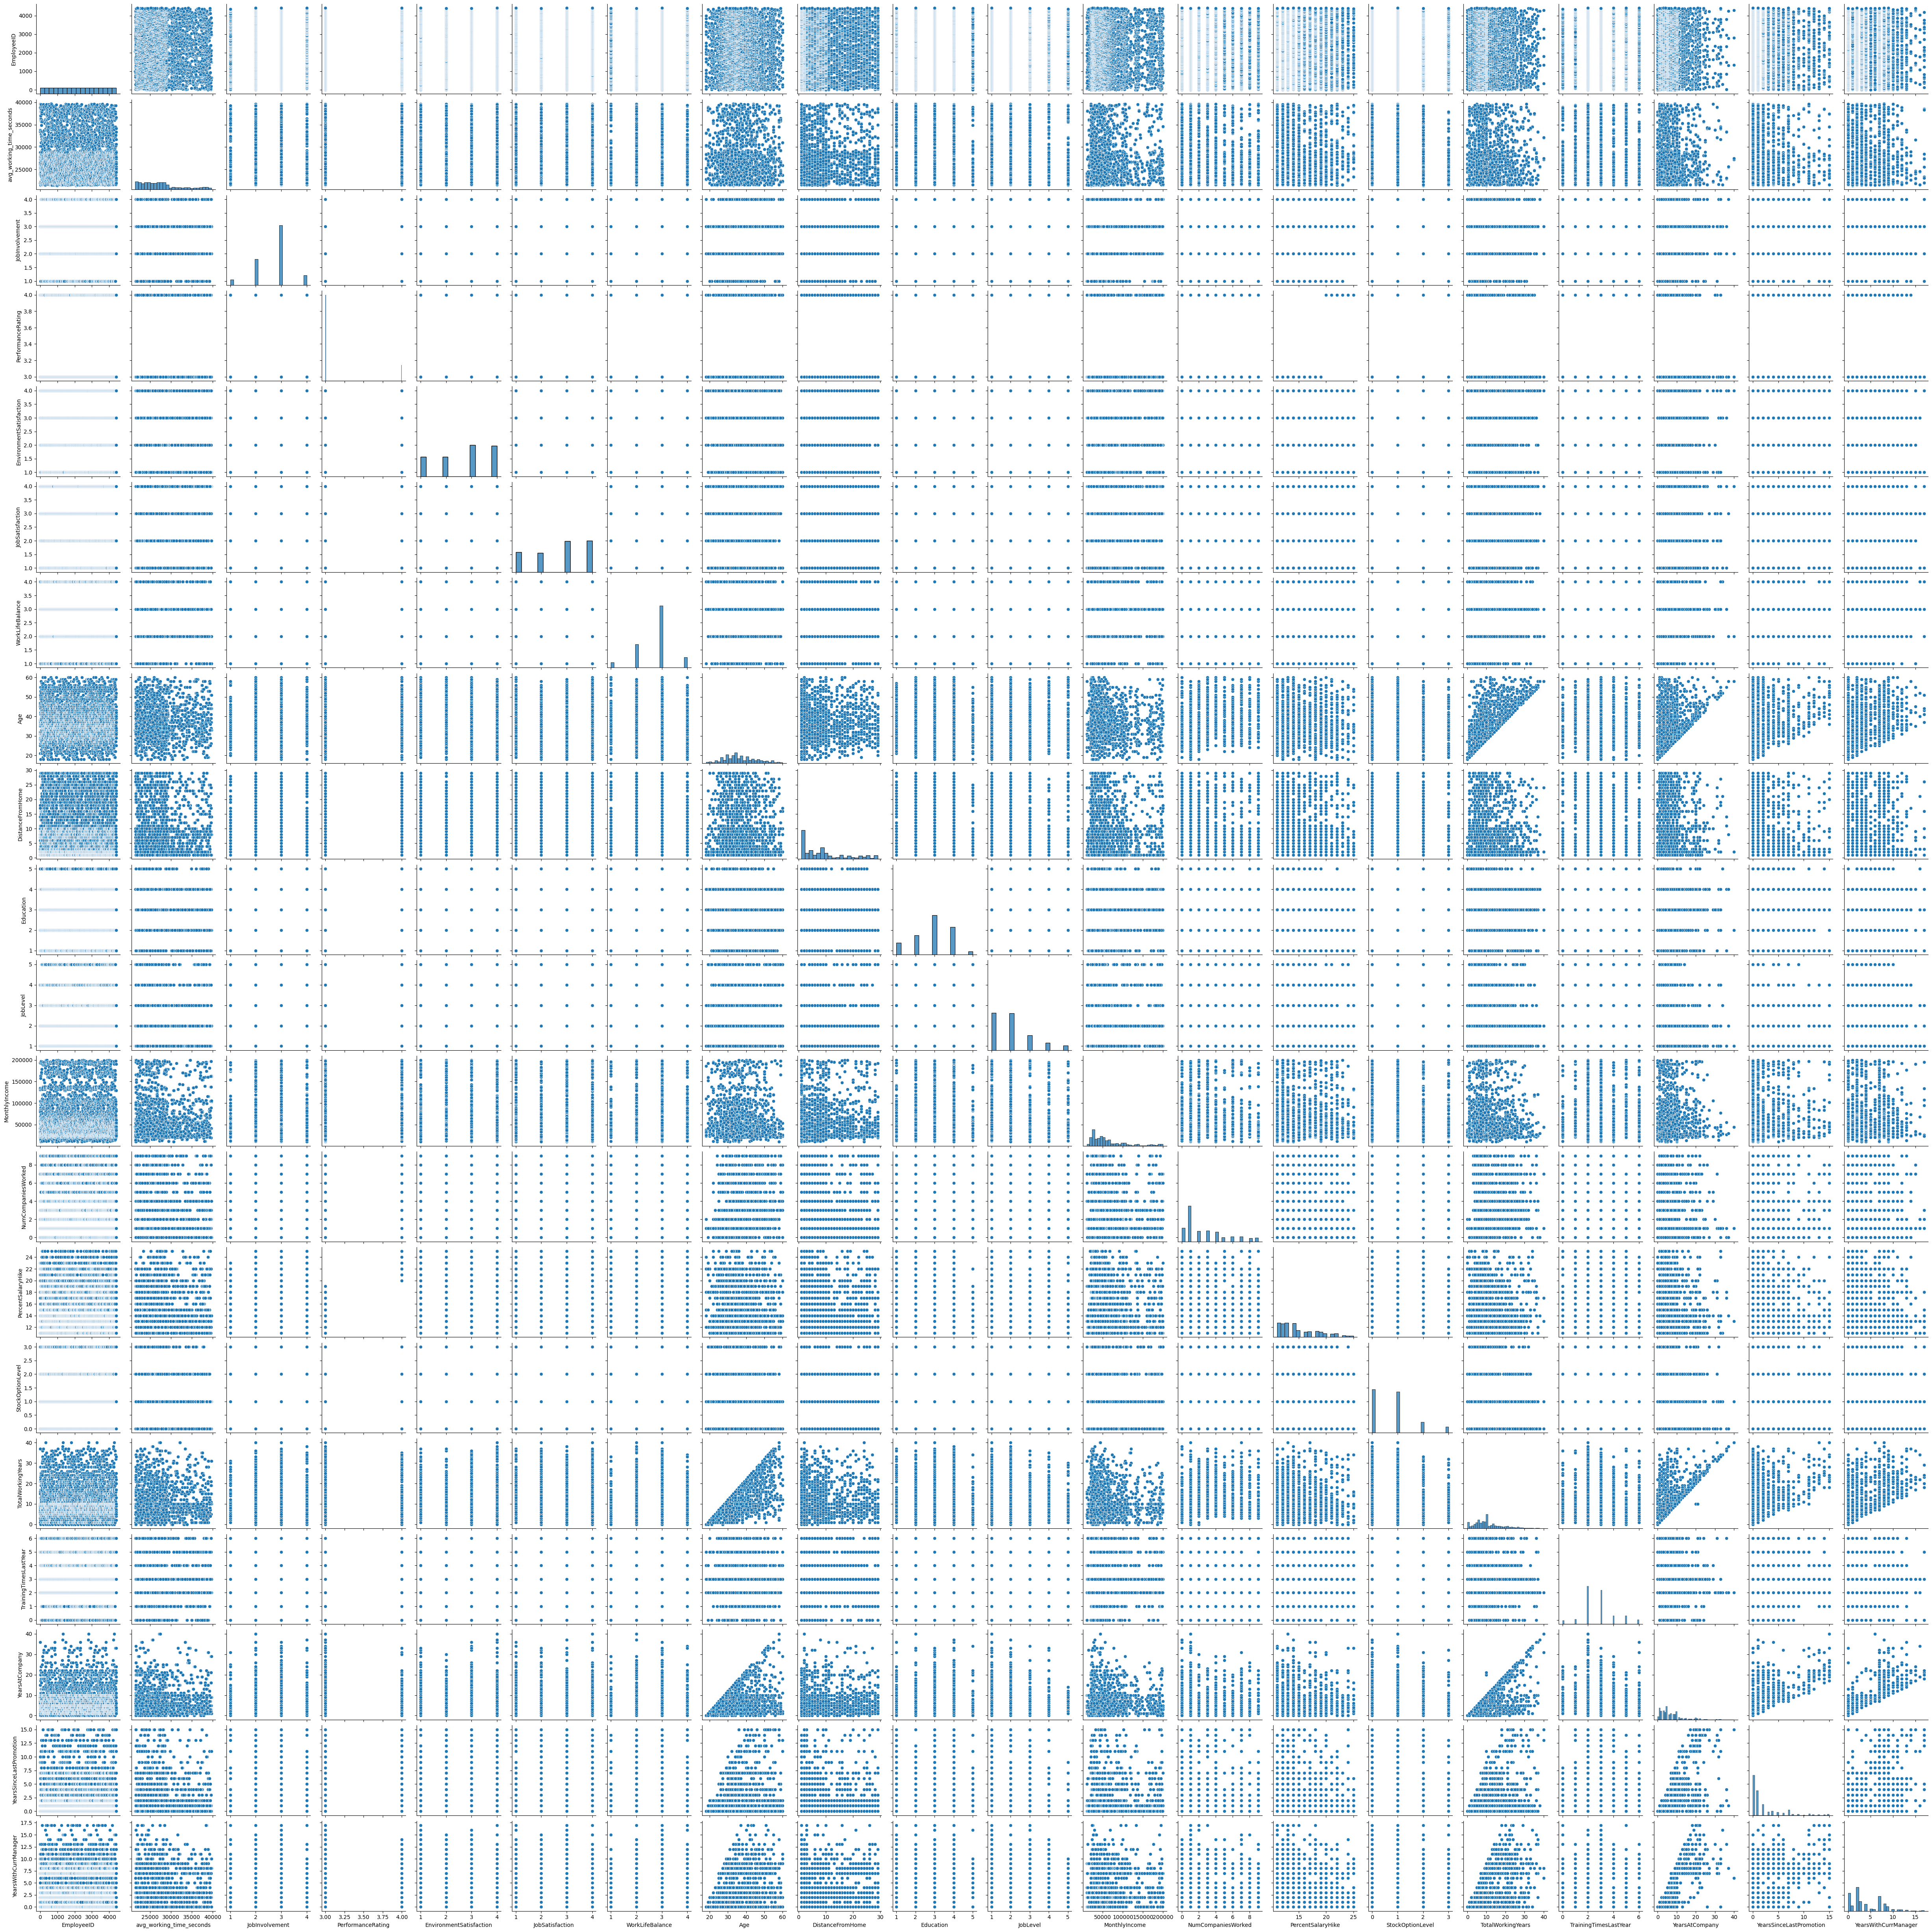

In [34]:
# Analyse bivariée de merged_global_data
plt.figure(figsize=(20, 4))
sns.pairplot(merged_global_data)
plt.show()

### Analyse par matrice de correlation

C:\Users\Agordien\AppData\Local\Temp\ipykernel_25396\815281888.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in merged_global_data_corel.select_dtypes(include=['object']).columns:


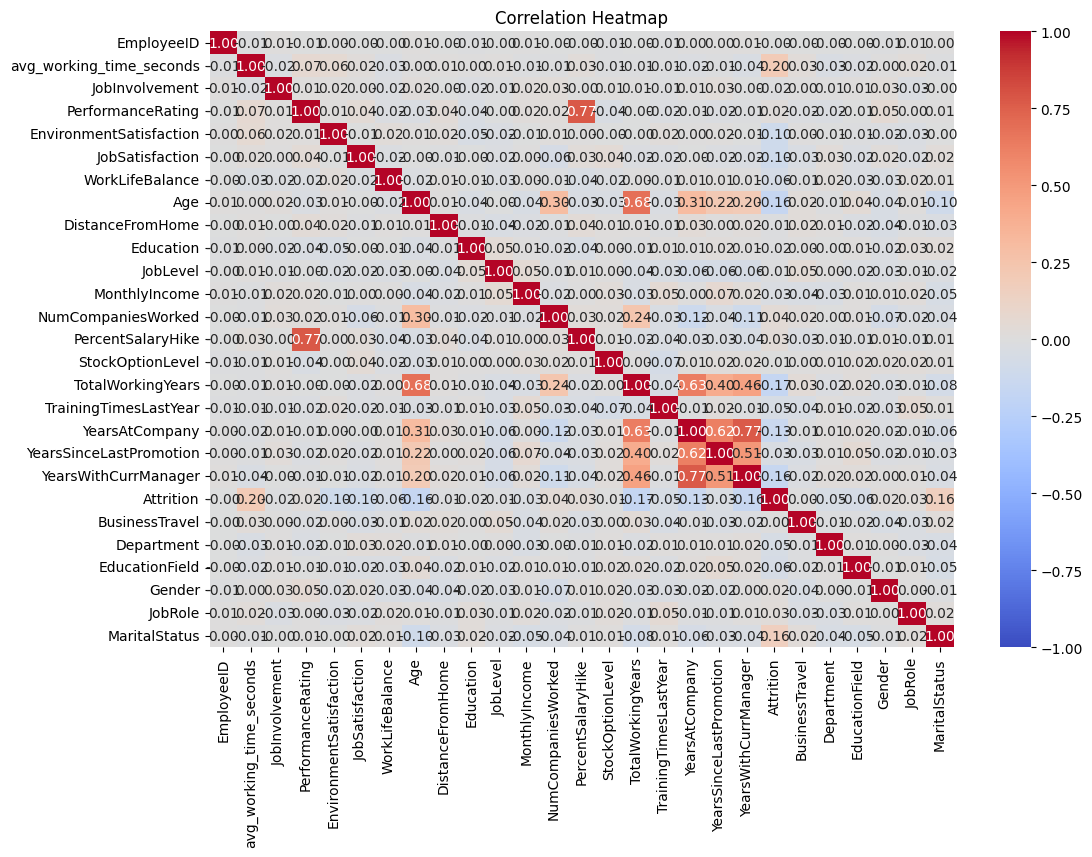

In [35]:
# Matrice de corrélation - Variables quantitatives continues uniquement
# Sélection des variables vraiment quantitatives (continues, pas catégorielles encodées)
quantitative_columns_global = ['Age', 'DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 
                               'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear',
                               'YearsAtCompany', 'YearsSinceLastPromotion', 'YearsWithCurrManager',
                               'avg_working_time_seconds']

# Ajouter la variable Attrition (déjà encodée en 0/1)
# On copie uniquement les colonnes quantitatives
merged_global_data_corel = merged_global_data.copy()
merged_global_data_corel['Attrition'] = merged_global_data_corel['Attrition'].map({'Yes': 1, 'No': 0})

# Filtrer pour ne garder que les colonnes quantitatives disponibles
quantitative_columns_global_available = [col for col in quantitative_columns_global if col in merged_global_data_corel.columns]
quantitative_columns_global_available.append('Attrition')  # Ajouter Attrition qui est maintenant numérique

# Sélectionner uniquement ces colonnes pour la corrélation
correlation_matrix = merged_global_data_corel[quantitative_columns_global_available].corr()

# Tracer la heatmap de corrélation
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap - Variables Quantitatives Continues')
plt.show()

## 4. Préparation des données pour le Machine Learning

### Encodage des variables catégorielles

In [36]:
# Sélection des colonnes catégorielles
global_data_cat = merged_global_data.select_dtypes(include=[object]).drop("Attrition", axis=1)

# Encodage one-hot des variables catégorielles
encoder = OneHotEncoder()
global_data_cat_encoded = pd.DataFrame(encoder.fit_transform(global_data_cat).toarray(), columns=encoder.get_feature_names_out(global_data_cat.columns))

# Vérification du résultat de l'encodage
global_data_cat_encoded.head()

C:\Users\Agordien\AppData\Local\Temp\ipykernel_25396\1897534736.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  global_data_cat = merged_global_data.select_dtypes(include=[object]).drop("Attrition", axis=1)


,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


### Normalisation des variables numériques

In [37]:
# Récuperation des données numériques
global_data_num = merged_global_data.select_dtypes(include=[np.number]).drop(["EmployeeID"], axis=1)

# Normalisation des colonnes numériques
scaler = StandardScaler()
global_data_num_scaled = pd.DataFrame(scaler.fit_transform(global_data_num), columns=global_data_num.columns)

# Vérification de la normalisation
global_data_num_scaled.head()

,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,-0.244050,0.379672,-0.426230,0.252200,1.156302,-1.085336,1.541369,-0.393938,-0.891688,-0.961486,1.405136,-0.678464,-1.150554,-0.932014,-1.322079,2.483396,-0.981014,-0.679146,-1.155935
1,0.013608,-1.026167,2.346151,0.252200,-0.663899,1.757749,-0.648668,0.099639,-1.868426,-0.961486,-0.491661,-1.079486,2.129306,0.241988,-0.678877,0.155707,-0.327893,-0.368715,-0.034520
2,-0.513108,0.379672,-0.426230,-0.665460,-0.663899,-2.506879,-0.539166,0.963398,1.061787,1.749610,2.725053,-0.678464,-0.057267,2.589994,-0.807517,-0.620189,-0.327893,-0.679146,-0.314873
3,-0.378371,-1.026167,-0.426230,1.169861,1.156302,0.336206,0.117845,-0.887515,2.038524,0.845911,0.386301,0.123580,-1.150554,2.589994,0.221606,1.707500,0.161947,1.493867,0.245834
4,0.227943,0.379672,-0.426230,1.169861,-1.573999,0.336206,-0.539166,0.099639,-1.868426,-0.961486,-0.884109,0.524602,-0.877232,1.415991,-0.292956,-0.620189,-0.164613,-0.679146,-0.034520


### Concaténation des données préparées

In [38]:
# Concatenation des colonnes numériques normalisées et des colonnes catégorielles encodées
merged_global_data_prepared = pd.concat([global_data_num_scaled, global_data_cat_encoded], axis=1)

label_encoder = LabelEncoder()

merged_global_data_prepared["Attrition"] = label_encoder.fit_transform(merged_global_data["Attrition"])
merged_global_data_prepared["EmployeeID"] = merged_global_data["EmployeeID"]

# Vérification des données préparées
merged_global_data_prepared.head()

,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Attrition,EmployeeID
0,-0.244050,0.379672,-0.426230,0.252200,1.156302,-1.085336,1.541369,-0.393938,-0.891688,-0.961486,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1
1,0.013608,-1.026167,2.346151,0.252200,-0.663899,1.757749,-0.648668,0.099639,-1.868426,-0.961486,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1,2
2,-0.513108,0.379672,-0.426230,-0.665460,-0.663899,-2.506879,-0.539166,0.963398,1.061787,1.749610,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0,3
3,-0.378371,-1.026167,-0.426230,1.169861,1.156302,0.336206,0.117845,-0.887515,2.038524,0.845911,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,4
4,0.227943,0.379672,-0.426230,1.169861,-1.573999,0.336206,-0.539166,0.099639,-1.868426,-0.961486,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0,5


## 5. Sauvegarde des données préparées

In [39]:
# Sauvegarde du dataset préparé
merged_global_data_prepared.to_csv('Data/prepared_data.csv', index=False)
print("Données préparées sauvegardées dans Data/prepared_data.csv")

Données préparées sauvegardées dans Data/prepared_data.csv


In [41]:
# Sauvegarde du dataset préparé sans certaines colonnes
columns_to_drop = ["Gender_Female", "Gender_Male", "MaritalStatus_Divorced", "MaritalStatus_Married", "MaritalStatus_Single"]
merged_global_data_prepared.drop(columns=columns_to_drop, inplace=True)
merged_global_data_prepared.to_csv('Data/prepared_data_no_gender_marital_status.csv', index=False)
print("Données préparées sans les colonnes 'Gender' et 'MaritalStatus' sauvegardées dans Data/prepared_data_no_gender_marital_status.csv")

Données préparées sans les colonnes 'Gender' et 'MaritalStatus' sauvegardées dans Data/prepared_data_no_gender_marital_status.csv


In [42]:
# Sauvegarde des encoders et scaler pour utilisation ultérieure
with open('Data/encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)
    
with open('Data/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
    
with open('Data/label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

print("Encoders et scaler sauvegardés!")

Encoders et scaler sauvegardés!


## Résumé

Ce notebook a permis de :
1. Importer et explorer les données brutes
2. Nettoyer et traiter les valeurs manquantes
3. Fusionner toutes les sources de données
4. Encoder les variables catégorielles
5. Normaliser les variables numériques
6. Sauvegarder les données préparées pour l'entraînement des modèles

Les données sont maintenant prêtes à être utilisées dans les notebooks suivants pour l'entraînement des modèles de Machine Learning.